# 0. Configuración y herramientas
Sección preliminar (no corresponde a una consigna): rutas, semillas, verificación de los archivos oficiales y el **evaluador local** que se usa en las consignas 2, 3 y 7.

### 0.1 Semillas, rutas y carga de archivos
Fija la semilla y las rutas, carga `sample_submission.csv`, `test_images.csv` y `questions_dev.jsonl`, y verifica que el envío tenga 80 filas (60 de test y 20 del benchmark) y que la GPU esté disponible.

In [1]:
import json, random
from pathlib import Path
import numpy as np
import pandas as pd

# --- Semillas ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# --- Rutas ---
COMP = Path("/kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas")
PATHS = {
    "dev_images":  COMP / "development" / "images",
    "dev_ann":     COMP / "development" / "annotations.json",   
    "test_images": COMP / "tpi_ia_2026_competition_public" / "test_images",
    "test_csv":    COMP / "tpi_ia_2026_competition_public" / "test_images.csv",
    "categories":  COMP / "tpi_ia_2026_competition_public" / "categories.csv",
    "questions":   COMP / "tpi_2026_qa_public" / "questions_dev.jsonl",
    "schema":      COMP / "scene_schema.json",
    "sample_sub":  COMP / "sample_submission.csv",
}
OUT = Path("/kaggle/working")
CONFIG = {"seed": SEED, "iou_thr": 0.5}

# --- Carga mínima ---
sample = pd.read_csv(PATHS["sample_sub"])
test_df = pd.read_csv(PATHS["test_csv"])
q_df = pd.DataFrame([json.loads(l) for l in open(PATHS["questions"])])

# --- Verificaciones de consistencia ---
sample_test  = set(sample.loc[sample["image_id"].str.startswith("test_"), "image_id"])
sample_bench = set(sample.loc[sample["image_id"].str.startswith("tpi_"), "image_id"])
q_files = set(q_df["image_file"].str.replace(".jpg", "", regex=False))

print("Filas del sample:", len(sample), "| test:", len(sample_test), "| benchmark:", len(sample_bench))
print("Preguntas:", len(q_df), "| imágenes con preguntas:", len(q_files))
print(q_df["type"].value_counts().to_string())
print("Benchmark del sample == imágenes de questions_dev:", sample_bench == q_files)
print("Columnas de test_images.csv:", list(test_df.columns))
print(test_df.head(3).to_string())

# --- GPU ---
import torch
print("CUDA:", torch.cuda.is_available(), "| GPUs:", torch.cuda.device_count())

Filas del sample: 80 | test: 60 | benchmark: 20
Preguntas: 60 | imágenes con preguntas: 20
type
description    20
count          10
existence      10
relation       10
position        5
size            5
Benchmark del sample == imágenes de questions_dev: True
Columnas de test_images.csv: ['image_id', 'file_name', 'width', 'height']
    image_id      file_name  width  height
0  test_0001  test_0001.jpg    425     640
1  test_0002  test_0002.jpg    427     640
2  test_0003  test_0003.jpg    427     640
CUDA: True | GPUs: 2


### 0.2 Consistencia del test y vocabulario
Verifica que las 60 imágenes de test coincidan con el sample, existan y tengan el tamaño declarado, y carga el vocabulario oficial (`categories.csv`) en `VOCAB`.

In [2]:
from PIL import Image

# 1) ids del test: CSV vs sample
csv_ids = set(test_df["image_id"])
print("Test CSV == test del sample:", csv_ids == sample_test)

# 2) archivos existentes y tamaños reales vs declarados
missing, mismatched = [], []
for r in test_df.itertuples():
    p = PATHS["test_images"] / r.file_name
    if not p.exists():
        missing.append(r.file_name)
        continue
    with Image.open(p) as im:
        if im.size != (r.width, r.height):
            mismatched.append((r.file_name, im.size, (r.width, r.height)))
print("Archivos faltantes:", missing)
print("Tamaños que no coinciden:", mismatched)

# 3) lo mismo para las 20 imágenes del benchmark en desarrollo
bench_files = sorted(q_df["image_file"].unique())
print("Benchmark: archivos existentes:",
      all((PATHS["dev_images"] / f).exists() for f in bench_files), "| total:", len(bench_files))

# 4) vocabulario oficial
categories = pd.read_csv(PATHS["categories"])
VOCAB = dict(zip(categories["category_id"], categories["category_name"]))
print("Vocabulario:", len(VOCAB), "categorías | ids de", min(VOCAB), "a", max(VOCAB))

Test CSV == test del sample: True
Archivos faltantes: []
Tamaños que no coinciden: []
Benchmark: archivos existentes: True | total: 20
Vocabulario: 120 categorías | ids de 1 a 120


**Resultado:** los archivos oficiales son consistentes (80 filas de envío, 60 imágenes de test válidas, 20 imágenes de benchmark que coinciden con `questions_dev.jsonl`) y el vocabulario tiene 120 categorías (ids 1 a 120). Las 60 consignas siguen la distribución del enunciado.

### 0.3 Evaluador local
"Corrector automático" que compara predicciones con las anotaciones de las 120 imágenes de desarrollo. Por imagen y categoría, recorre las predicciones de mayor a menor confianza y empareja cada una con el objeto real libre de mayor IoU, si es ≥ 0,5 (**TP**). Las predicciones sin pareja se clasifican con la política LVIS (**FP** o **ignoradas**, ver 1.1) y los objetos sin pareja son **FN**. Calcula precisión, recall, F1 y cobertura, en cajas y en máscaras.

| Dato | Anotaciones | Predicciones (SceneJSON) | Formato común |
|---|---|---|---|
| Caja | `[x, y, ancho, alto]` | `[x1, y1, x2, y2]` | `[x1, y1, x2, y2]` |
| Máscara | Polígonos | RLE no comprimido, column-major | RLE de `pycocotools` |

`gt_index` guarda las anotaciones reorganizadas por imagen, con sus listas LVIS. Es ground truth: solo lo usa el evaluador, nunca la inferencia.

In [3]:
# Ground truth: solo para EDA y evaluación, nunca para inferencia
gt_ann = json.load(open(PATHS["dev_ann"]))

from pycocotools import mask as mask_utils

#====================================================================
# CONVERSIONES
#====================================================================

def xywh_a_xyxy(b):
    x, y, w, h = b
    return [x, y, x + w, y + h]

def poligonos_a_rle(seg, h, w):
    return mask_utils.merge(mask_utils.frPyObjects(seg, h, w))

def rle_scene_a_rle(m):
    """Máscara del SceneJSON {'size':[h,w], 'counts':[...]} -> RLE comprimido de pycocotools."""
    h, w = m["size"]
    return mask_utils.frPyObjects({"size": [int(h), int(w)], "counts": [int(c) for c in m["counts"]]}, h, w)

def mascara_a_rle_scene(mascara):
    """Matriz binaria (alto x ancho) -> {'size':[alto, ancho], 'counts':[...]} column-major, empezando por ceros."""
    m = np.asarray(mascara, dtype=np.uint8)
    h, w = m.shape
    plano = m.flatten(order="F")                       # column-major
    cambios = np.flatnonzero(np.diff(plano)) + 1
    limites = np.concatenate([[0], cambios, [plano.size]])
    counts = np.diff(limites).tolist()
    if plano[0] == 1:                                  # el primer conteo siempre es de ceros
        counts = [0] + counts
    return {"size": [int(h), int(w)], "counts": [int(c) for c in counts]}

# ---------- Índice del ground truth (solo para evaluar) ----------
def construir_gt_index(gt_ann):
    imgs = {im["id"]: im for im in gt_ann["images"]}
    index = {}
    for im in gt_ann["images"]:
        clave = Path(im["file_name"]).stem             # 'tpi_0001'
        index[clave] = {"h": im["height"], "w": im["width"], "objetos": [],
                        "N": set(im["neg_category_ids"]),
                        "E": set(im["not_exhaustive_category_ids"])}
    for a in gt_ann["annotations"]:
        g = index[Path(imgs[a["image_id"]]["file_name"]).stem]
        g["objetos"].append({
            "ann_id": a["id"],
            "category_id": a["category_id"],
            "bbox": xywh_a_xyxy(a["bbox"]),
            "rle": poligonos_a_rle(a["segmentation"], g["h"], g["w"]),
        })
    for g in index.values():
        g["P"] = {o["category_id"] for o in g["objetos"]}
    return index

gt_index = construir_gt_index(gt_ann)

#====================================================================
# CORREGIR UNA IMAGEN
#====================================================================

def xyxy_a_xywh(b):
    x1, y1, x2, y2 = b
    return [x1, y1, x2 - x1, y2 - y1]

def situacion_lvis(cat, g):
    """Qué hacer con una predicción SIN pareja de la categoría `cat` en la imagen `g`."""
    if cat in g["N"]:
        return "fp"                                   # verificada como ausente
    if cat in g["P"]:
        return "ign" if cat in g["E"] else "fp"       # anotada: completa -> FP, no exhaustiva -> se ignora
    return "ign"                                      # nadie la verificó

def evaluar_imagen(pred_objs, g, tipo="bbox", iou_thr=0.5):
    """Corrige una imagen. pred_objs: objetos en formato SceneJSON. g: entrada de gt_index."""
    total = {"tp": 0, "fp": 0, "fn": 0, "ign": 0}
    por_cat, detalle = {}, []

    for c in {p["category_id"] for p in pred_objs} | g["P"]:
        preds = sorted([p for p in pred_objs if p["category_id"] == c], key=lambda p: -p["confidence"])
        gts = [o for o in g["objetos"] if o["category_id"] == c]

        # matriz de IoU (filas = predicciones, columnas = objetos reales)
        if preds and gts:
            if tipo == "bbox":
                d = [xyxy_a_xywh(p["bbox"]) for p in preds]
                r = [xyxy_a_xywh(o["bbox"]) for o in gts]
            else:
                for p in preds:
                    if list(p["mask"]["size"]) != [g["h"], g["w"]]:
                        raise ValueError(f"Máscara de tamaño {p['mask']['size']} en imagen de {[g['h'], g['w']]}")
                d = [rle_scene_a_rle(p["mask"]) for p in preds]
                r = [o["rle"] for o in gts]
            ious = np.array(mask_utils.iou(d, r, [0] * len(gts)))
        else:
            ious = np.zeros((len(preds), len(gts)))

        cnt = {"tp": 0, "fp": 0, "fn": 0, "ign": 0}
        usado = np.zeros(len(gts), dtype=bool)
        for i, p in enumerate(preds):
            candidatos = [j for j in range(len(gts)) if not usado[j] and ious[i, j] >= iou_thr]
            if candidatos:
                j = max(candidatos, key=lambda j: ious[i, j])
                usado[j] = True
                res = "tp"
            else:
                res = situacion_lvis(c, g)
            cnt[res] += 1
            detalle.append({"pred_id": p["id"], "category_id": c, "resultado": res,
                            "iou_max": float(ious[i].max()) if len(gts) else 0.0})
        cnt["fn"] = int((~usado).sum())

        por_cat[c] = cnt
        for k in total:
            total[k] += cnt[k]
    return total, por_cat, detalle

def gt_como_pred(clave):
    """Convierte las anotaciones de una imagen al formato de predicción. SOLO para probar el evaluador."""
    return [{"id": f"gt_{o['ann_id']}", "category_id": o["category_id"], "confidence": 1.0,
             "bbox": o["bbox"], "mask": mascara_a_rle_scene(mask_utils.decode(o["rle"]))}
            for o in gt_index[clave]["objetos"]]


#====================================================================
# NOTA GLOBAL
#====================================================================

def calcular_metricas(c):
    tp, fp, fn, ign = c["tp"], c["fp"], c["fn"], c["ign"]
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    n_pred = tp + fp + ign
    cobertura = (tp + fp) / n_pred if n_pred else float("nan")
    return {"precision": precision, "recall": recall, "f1": f1, "cobertura": cobertura, **c}

def evaluar(predicciones, claves=None, iou_thr=0.5, tipos=("bbox", "mask")):
    """predicciones: dict {image_id: SceneJSON (con 'objects') o lista de objetos}.
    Una imagen sin predicciones cuenta como 'no encontró nada'."""
    claves = claves or sorted(gt_index)
    resumen, filas_img, filas_cat, detalles = {}, [], [], []
    for tipo in tipos:
        total = {"tp": 0, "fp": 0, "fn": 0, "ign": 0}
        por_cat = {}
        for k in claves:
            pred = predicciones.get(k, [])
            objs = pred["objects"] if isinstance(pred, dict) else pred
            t, pc, det = evaluar_imagen(objs, gt_index[k], tipo, iou_thr)
            for x in total:
                total[x] += t[x]
            for c, cnt in pc.items():
                acc = por_cat.setdefault(c, {"tp": 0, "fp": 0, "fn": 0, "ign": 0})
                for x in acc:
                    acc[x] += cnt[x]
            filas_img.append({"tipo": tipo, "image_id": k, **calcular_metricas(t)})
            detalles += [{"tipo": tipo, "image_id": k, **d} for d in det]
        resumen[tipo] = calcular_metricas(total)
        filas_cat += [{"tipo": tipo, "category_id": c, "category": VOCAB[c], **calcular_metricas(cnt)}
                      for c, cnt in por_cat.items()]

    res = {"resumen": pd.DataFrame(resumen).T,
           "por_imagen": pd.DataFrame(filas_img),
           "por_categoria": pd.DataFrame(filas_cat),
           "detalle": pd.DataFrame(detalles)}
    res["resumen"]["f1_medio_por_imagen"] = res["por_imagen"].groupby("tipo")["f1"].mean()
    return res

def mostrar(res):
    cols = ["f1", "precision", "recall", "cobertura", "f1_medio_por_imagen", "tp", "fp", "fn", "ign"]
    print(res["resumen"][cols].astype(float).round(3).to_string())


print("Evaluador listo | imágenes en gt_index:", len(gt_index),
      "| objetos:", sum(len(g["objetos"]) for g in gt_index.values()))

Evaluador listo | imágenes en gt_index: 120 | objetos: 1790


### 0.4 Pruebas del evaluador
Le damos respuestas con resultado conocido y verificamos que el evaluador lo reproduzca.

| Prueba | Qué se le da | Resultado esperado |
|---|---|---|
| 0a. RLE de la cátedra | Máscara de ejemplo de `sample_submission.csv` | Un único píxel en la esquina superior izquierda |
| 0b. Ida y vuelta | Las 1790 máscaras convertidas a RLE y de vuelta | Ninguna cambia |
| 0c. Perfecta | Las anotaciones como predicción | F1 = 1 |
| 1. En blanco | Sin predicciones | 1790 FN, F1 = 0 |
| 2. Categoría ausente | Marca extra de una categoría de `neg_category_ids` | Cuenta como FP |
| 3. No verificada | Marca extra de una categoría no revisada | Se ignora; F1 = 1 |
| 4. Duplicados | Un duplicado por categoría anotada | FP, o se ignora si es no exhaustiva |
| 5-6. Caja corrida | Imagen inventada, IoU ≈ 0,67 y ≈ 0,33 | Acierto / FP + FN |
| 7. Máscara mala | Caja exacta, máscara de 1/4 | Acierto en cajas, FP + FN en máscaras |

In [4]:
resultados_pruebas = []

def comprobar(nombre, tipo, obtenido, esperado):
    ok = all(abs(float(obtenido[k]) - v) < 1e-6 for k, v in esperado.items())
    resultados_pruebas.append({"prueba": nombre, "tipo": tipo, "esperado": esperado,
                               "obtenido": {k: round(float(obtenido[k]), 3) for k in esperado},
                               "OK": ok})

def correr(nombre, preds, esperado):
    res = evaluar(preds)["resumen"]
    for tipo in ["bbox", "mask"]:
        comprobar(nombre, tipo, res.loc[tipo], esperado)

def marca_extra(base, categoria, ident):
    nueva = dict(base)                       # misma caja y máscara que un objeto real
    nueva.update({"id": ident, "category_id": categoria, "confidence": 0.5})
    return nueva

def gt_como_pred(clave):
    """Anotaciones de una imagen en formato de predicción. SOLO para probar el evaluador."""
    return [{"id": f"gt_{o['ann_id']}", "category_id": o["category_id"], "confidence": 1.0,
             "bbox": o["bbox"], "mask": mascara_a_rle_scene(mask_utils.decode(o["rle"]))}
            for o in gt_index[clave]["objetos"]]

# ---------- Prueba 0a: RLE de ejemplo de la cátedra ----------
ej = mask_utils.decode(rle_scene_a_rle(json.loads(sample.iloc[0]["SceneJSON"])["objects"][0]["mask"]))
ok0a = ej.shape == (640, 425) and int(ej.sum()) == 1 and bool(ej[0, 0])
resultados_pruebas.append({"prueba": "0a. RLE de la cátedra", "tipo": "-",
                           "esperado": {"forma": (640, 425), "pixeles": 1, "esquina": True},
                           "obtenido": {"forma": ej.shape, "pixeles": int(ej.sum()), "esquina": bool(ej[0, 0])},
                           "OK": ok0a})

# ---------- Prueba 0b: ida y vuelta de las 1790 máscaras ----------
fallas = 0
for g in gt_index.values():
    for o in g["objetos"]:
        original = mask_utils.decode(o["rle"])
        vuelta = mask_utils.decode(rle_scene_a_rle(mascara_a_rle_scene(original)))
        if not np.array_equal(original, vuelta):
            fallas += 1
resultados_pruebas.append({"prueba": "0b. Ida y vuelta RLE", "tipo": "mask",
                           "esperado": {"fallas": 0}, "obtenido": {"fallas": fallas}, "OK": fallas == 0})

# ---------- Prueba 0c: predicción perfecta ----------
preds_perfectas = {k: gt_como_pred(k) for k in gt_index}
correr("0c. Perfecta", preds_perfectas, {"tp": 1790, "fp": 0, "fn": 0, "ign": 0, "f1": 1})

# ---------- Prueba 1: en blanco ----------
correr("1. En blanco", {}, {"tp": 0, "fp": 0, "fn": 1790, "ign": 0, "f1": 0})

# ---------- Prueba 2: categoría verificada como ausente ----------
preds, n_fp = {}, 0
for k, g in gt_index.items():
    p = list(preds_perfectas[k])
    if g["N"]:
        p.append(marca_extra(p[0], min(g["N"]), "extra_neg"))
        n_fp += 1
    preds[k] = p
correr("2. Categoría ausente", preds, {"tp": 1790, "fp": n_fp, "fn": 0, "ign": 0})

# ---------- Prueba 3: categoría no verificada ----------
preds = {}
for k, g in gt_index.items():
    no_verificada = min(c for c in VOCAB if c not in g["P"] | g["N"])
    preds[k] = list(preds_perfectas[k]) + [marca_extra(preds_perfectas[k][0], no_verificada, "extra_nv")]
correr("3. No verificada", preds, {"tp": 1790, "fp": 0, "fn": 0, "ign": len(gt_index), "f1": 1})

# ---------- Prueba 4: duplicados ----------
preds, n_fp, n_ign = {}, 0, 0
for k, g in gt_index.items():
    p = list(preds_perfectas[k])
    for c in g["P"]:
        original = next(o for o in preds_perfectas[k] if o["category_id"] == c)
        p.append(marca_extra(original, c, f"dup_{c}"))
        if c in g["E"]:
            n_ign += 1
        else:
            n_fp += 1
    preds[k] = p
correr("4. Duplicados", preds, {"tp": 1790, "fp": n_fp, "fn": 0, "ign": n_ign})

# ---------- Pruebas 5 a 7: imagen inventada de 100 x 100 ----------
def rectangulo(caja, h=100, w=100):
    m = np.zeros((h, w), dtype=np.uint8)
    x1, y1, x2, y2 = caja
    m[y1:y2, x1:x2] = 1
    return m

REAL = [10, 10, 30, 30]                      # cuadrado de 20 x 20
g_falsa = {"h": 100, "w": 100, "P": {1}, "N": set(), "E": set(),
           "objetos": [{"ann_id": 0, "category_id": 1, "bbox": REAL,
                        "rle": rle_scene_a_rle(mascara_a_rle_scene(rectangulo(REAL)))}]}

def pred_falsa(caja, caja_mascara):
    return [{"id": "p0", "category_id": 1, "confidence": 0.9, "bbox": caja,
             "mask": mascara_a_rle_scene(rectangulo(caja_mascara))}]

casos = [
    ("5. Caja corrida 4 px",  [14, 10, 34, 30], [14, 10, 34, 30],
     {"bbox": {"tp": 1, "fp": 0, "fn": 0}, "mask": {"tp": 1, "fp": 0, "fn": 0}}),
    ("6. Caja corrida 10 px", [20, 10, 40, 30], [20, 10, 40, 30],
     {"bbox": {"tp": 0, "fp": 1, "fn": 1}, "mask": {"tp": 0, "fp": 1, "fn": 1}}),
    ("7. Máscara de 1/4",     REAL,             [10, 10, 15, 30],
     {"bbox": {"tp": 1, "fp": 0, "fn": 0}, "mask": {"tp": 0, "fp": 1, "fn": 1}}),
]
for nombre, caja, caja_mascara, esperado in casos:
    for tipo in ["bbox", "mask"]:
        total, _, _ = evaluar_imagen(pred_falsa(caja, caja_mascara), g_falsa, tipo=tipo)
        comprobar(nombre, tipo, total, esperado[tipo])

# ---------- Resumen ----------
tabla_pruebas = pd.DataFrame(resultados_pruebas)
print(tabla_pruebas.to_string(index=False))
print("\nTodas las pruebas OK:", bool(tabla_pruebas["OK"].all()))

               prueba tipo                                             esperado                                                      obtenido   OK
0a. RLE de la cátedra    - {'forma': (640, 425), 'pixeles': 1, 'esquina': True}          {'forma': (640, 425), 'pixeles': 1, 'esquina': True} True
 0b. Ida y vuelta RLE mask                                        {'fallas': 0}                                                 {'fallas': 0} True
         0c. Perfecta bbox    {'tp': 1790, 'fp': 0, 'fn': 0, 'ign': 0, 'f1': 1}   {'tp': 1790.0, 'fp': 0.0, 'fn': 0.0, 'ign': 0.0, 'f1': 1.0} True
         0c. Perfecta mask    {'tp': 1790, 'fp': 0, 'fn': 0, 'ign': 0, 'f1': 1}   {'tp': 1790.0, 'fp': 0.0, 'fn': 0.0, 'ign': 0.0, 'f1': 1.0} True
         1. En blanco bbox    {'tp': 0, 'fp': 0, 'fn': 1790, 'ign': 0, 'f1': 0}   {'tp': 0.0, 'fp': 0.0, 'fn': 1790.0, 'ign': 0.0, 'f1': 0.0} True
         1. En blanco mask    {'tp': 0, 'fp': 0, 'fn': 1790, 'ign': 0, 'f1': 0}   {'tp': 0.0, 'fp': 0.0, 'fn': 1790.0,

**Resultado:** las 17 comprobaciones dan `OK`. El evaluador lee el RLE igual que la cátedra, cuenta los objetos perdidos, aplica la política LVIS (74 FP por categorías ausentes; duplicados: 717 FP y 47 ignorados en categorías no exhaustivas), respeta el umbral IoU ≥ 0,5, empareja cada objeto real una sola vez y corrige cajas y máscaras por separado.

**Decisiones:** emparejamiento por confianza descendente; nota principal = F1 global (suma de TP, FP y FN de todas las imágenes), reportando también el F1 medio por imagen porque no sabemos cuál usa Kaggle.

# 1. Análisis exploratorio del dataset
Caracterizamos las 120 imágenes de desarrollo para fundamentar las decisiones posteriores. Cada bloque responde una pregunta y termina con la decisión que motiva. Las anotaciones se usan solo para este análisis y para medir, nunca para predecir.

### 1.1 Anotaciones y política de evaluación LVIS
`annotations.json` es el *ground truth* de las 120 imágenes: categoría, caja y máscara de cada objeto, más dos listas por imagen. LVIS no revisa todas las categorías en cada imagen, así que **que una categoría no esté anotada no prueba que el objeto no exista**.

| Conjunto | Qué indica |
|---|---|
| Positivas (`P`) | Categorías con al menos una instancia anotada |
| `neg_category_ids` (`N`) | Verificadas como **ausentes** |
| `not_exhaustive_category_ids` (`E`) | Presentes, pero **puede haber instancias sin anotar** |

Una **predicción sin pareja** se evalúa según su categoría:

| Situación | Predicción sin pareja |
|---|---|
| Positiva (exhaustiva) | Falso positivo |
| Positiva no exhaustiva | Se ignora |
| Negativa verificada | Falso positivo |
| No verificada | Se ignora |

Un **objeto anotado sin pareja** es siempre falso negativo. Los verdaderos negativos no se cuentan. Como las predicciones ignoradas no suman ni restan, la precisión se informa junto con la **cobertura** (fracción de predicciones que se pudieron juzgar).

**Uso permitido:** EDA y métricas. **Prohibido:** usarlas para elegir clases, completar o corregir objetos, construir el SceneJSON o responder preguntas.

### 1.2 Estructura y consistencia de las anotaciones
Muestra el formato de las anotaciones, verifica que sus categorías coincidan con `VOCAB`, que todas las imágenes tengan las listas LVIS y que se cumplan los supuestos de la política (`P` y `N` disjuntos, `E` ⊆ `P`). Construye `df_img`, con una fila por imagen.

In [5]:
# gt_ann (ground truth) se cargó en 0.3

print("Claves de nivel superior:", list(gt_ann.keys()))
print("Imágenes:", len(gt_ann["images"]),
      "| anotaciones:", len(gt_ann["annotations"]),
      "| categorías:", len(gt_ann["categories"]))

print("\n--- Ejemplo de imagen ---")
print(json.dumps(gt_ann["images"][0], indent=2, ensure_ascii=False))

print("\n--- Ejemplo de anotación ---")
a = dict(gt_ann["annotations"][0])
seg = a.get("segmentation")
if isinstance(seg, dict):
    a["segmentation"] = {"tipo": "RLE", "size": seg.get("size"), "counts": str(seg.get("counts"))[:60] + "..."}
elif isinstance(seg, list):
    a["segmentation"] = {"tipo": "polígonos", "n_polígonos": len(seg)}
print(json.dumps(a, indent=2, ensure_ascii=False))

# --- 1) ids y nombres de categoría: anotaciones vs vocabulario oficial ---
gt_cats = {c["id"]: c["name"] for c in gt_ann["categories"]}
print("Categorías idénticas (id y nombre) a VOCAB:", gt_cats == VOCAB)
print("Categoría 86:", VOCAB.get(86))

ann_cat_ids = {a["category_id"] for a in gt_ann["annotations"]}
print("category_id en anotaciones fuera del vocabulario:", sorted(ann_cat_ids - set(VOCAB)))
print("Categorías con al menos una instancia:", len(ann_cat_ids), "de", len(VOCAB))

# --- 2) metadata LVIS y nombres de archivo ---
sin_neg = [im["id"] for im in gt_ann["images"] if "neg_category_ids" not in im]
sin_nex = [im["id"] for im in gt_ann["images"] if "not_exhaustive_category_ids" not in im]
print("\nImágenes sin neg_category_ids:", sin_neg)
print("Imágenes sin not_exhaustive_category_ids:", sin_nex)
patron_ok = all(im["file_name"] == f"tpi_{im['id']:04d}.jpg" for im in gt_ann["images"])
print("file_name sigue el patrón tpi_<id con 4 dígitos>.jpg:", patron_ok)

# --- 3) tipos de máscara y objetos 'crowd' ---
tipos = pd.Series(["RLE" if isinstance(a["segmentation"], dict) else "polígonos"
                   for a in gt_ann["annotations"]]).value_counts()
print("\nTipo de segmentation:\n" + tipos.to_string())
print("Anotaciones con iscrowd=1:", sum(a["iscrowd"] == 1 for a in gt_ann["annotations"]))

# --- 4) tabla por imagen (ground truth) ---
filas = []
for im in gt_ann["images"]:
    anns = [a for a in gt_ann["annotations"] if a["image_id"] == im["id"]]
    filas.append({
        "image_id": im["id"],
        "file_name": im["file_name"],
        "width": im["width"],
        "height": im["height"],
        "n_inst": len(anns),
        "n_cats": len({a["category_id"] for a in anns}),
        "n_neg": len(im["neg_category_ids"]),
        "n_not_exh": len(im["not_exhaustive_category_ids"]),
    })
df_img = pd.DataFrame(filas)
print("\n", df_img.head().to_string(index=False))
print("\n", df_img[["n_inst", "n_cats", "n_neg", "n_not_exh"]].describe().round(1).to_string())

# P = categorías con anotaciones, N = negativas, E = no exhaustivas
pos_por_img = {}
for a in gt_ann["annotations"]:
    pos_por_img.setdefault(a["image_id"], set()).add(a["category_id"])

solapan_P_N, E_fuera_de_P, ids_invalidos = [], [], []
for im in gt_ann["images"]:
    P = pos_por_img.get(im["id"], set())
    N = set(im["neg_category_ids"])
    E = set(im["not_exhaustive_category_ids"])
    if P & N:
        solapan_P_N.append(im["id"])
    if not E <= P:
        E_fuera_de_P.append(im["id"])
    if (N | E) - set(VOCAB):
        ids_invalidos.append(im["id"])

print("Imágenes donde P y N se solapan:", solapan_P_N)
print("Imágenes donde E no es subconjunto de P:", E_fuera_de_P)
print("Imágenes con ids de N o E fuera del vocabulario:", ids_invalidos)
print("Imágenes sin ninguna anotación:",
      [im["id"] for im in gt_ann["images"] if im["id"] not in pos_por_img])

# Fracción del vocabulario que LVIS permite verificar por imagen (P ∪ N)
verificables = [len(pos_por_img.get(im["id"], set()) | set(im["neg_category_ids"]))
                for im in gt_ann["images"]]
media = sum(verificables) / len(verificables)
print("\nCategorías verificables por imagen (media):", round(media, 1),
      "de", len(VOCAB), "| fracción:", round(media / len(VOCAB), 3))

Claves de nivel superior: ['info', 'licenses', 'images', 'categories', 'annotations']
Imágenes: 120 | anotaciones: 1790 | categorías: 120

--- Ejemplo de imagen ---
{
  "id": 1,
  "file_name": "tpi_0001.jpg",
  "width": 480,
  "height": 640,
  "license": 3,
  "neg_category_ids": [
    1,
    7
  ],
  "not_exhaustive_category_ids": []
}

--- Ejemplo de anotación ---
{
  "id": 1,
  "image_id": 1,
  "category_id": 86,
  "bbox": [
    148.14,
    69.52,
    198.41,
    160.86
  ],
  "segmentation": {
    "tipo": "polígonos",
    "n_polígonos": 1
  },
  "area": 31077.0,
  "iscrowd": 0
}
Categorías idénticas (id y nombre) a VOCAB: True
Categoría 86: mirror
category_id en anotaciones fuera del vocabulario: []
Categorías con al menos una instancia: 120 de 120

Imágenes sin neg_category_ids: []
Imágenes sin not_exhaustive_category_ids: []
file_name sigue el patrón tpi_<id con 4 dígitos>.jpg: True

Tipo de segmentation:
polígonos    1790
Anotaciones con iscrowd=1: 0

  image_id    file_name  wid

**Resultado:** el archivo sigue el formato COCO (120 imágenes, 1790 anotaciones), con cajas `xywh` y máscaras como polígonos (ninguna `iscrowd`). Sus categorías son idénticas a `VOCAB` y las 120 tienen instancias. Los supuestos LVIS se cumplen en todas las imágenes, pero solo **7,3 de 120 categorías son verificables por imagen** (6,1 %).

**Decisiones:** convertir las cajas a `xyxy` para el SceneJSON; reportar la precisión junto con la cobertura y priorizar el recall.

### 1.3 Instancias por imagen
**Pregunta:** ¿cuántos objetos hay por imagen y cuánto varía? **Decisión que informa:** límite de detecciones y NMS.

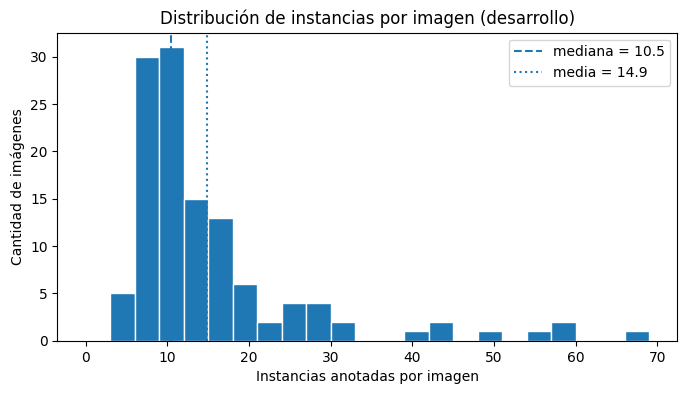

Imágenes con 20 o más instancias: 22 de 120
Imágenes con 30 o más instancias: 10 de 120

Las 5 imágenes más cargadas:
 image_id    file_name  n_inst  n_cats
       50 tpi_0050.jpg      66       8
       78 tpi_0078.jpg      57       8
      100 tpi_0100.jpg      57       7
       43 tpi_0043.jpg      54       3
       97 tpi_0097.jpg      50       8

Verificación: suma de n_inst = 1790 | anotaciones = 1790


In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df_img["n_inst"], bins=range(0, df_img["n_inst"].max() + 5, 3), edgecolor="white")
ax.axvline(df_img["n_inst"].median(), linestyle="--", label=f"mediana = {df_img['n_inst'].median():.1f}")
ax.axvline(df_img["n_inst"].mean(), linestyle=":", label=f"media = {df_img['n_inst'].mean():.1f}")
ax.set_xlabel("Instancias anotadas por imagen")
ax.set_ylabel("Cantidad de imágenes")
ax.set_title("Distribución de instancias por imagen (desarrollo)")
ax.legend()
plt.show()

print("Imágenes con 20 o más instancias:", int((df_img["n_inst"] >= 20).sum()), "de", len(df_img))
print("Imágenes con 30 o más instancias:", int((df_img["n_inst"] >= 30).sum()), "de", len(df_img))
print("\nLas 5 imágenes más cargadas:")
print(df_img.nlargest(5, "n_inst")[["image_id", "file_name", "n_inst", "n_cats"]].to_string(index=False))

print("\nVerificación: suma de n_inst =", int(df_img["n_inst"].sum()), "| anotaciones =", len(gt_ann["annotations"]))

**Resultado:** mediana 10,5 y media 14,9 objetos por imagen, con cola larga: 22 imágenes tienen 20 o más y el máximo es 66. La imagen 43 concentra 54 instancias en 3 categorías (objetos repetidos).

**Decisiones:** no limitar las detecciones a un valor bajo (el schema admite 300); tratar el NMS con cuidado en escenas densas.

### 1.4 Tamaño de los objetos
**Pregunta:** ¿qué fracción de la imagen ocupa cada objeto? **Decisión que informa:** resolución de entrada y definición de `size`.

Calcula `area_ratio = area / (ancho × alto)`, verifica que `area` sea el área de la máscara (no de la caja) y compara con los umbrales de tamaño de COCO.

Instancias: 1790
count    1790.0000
mean        0.0190
std         0.0518
min         0.0000
5%          0.0001
25%         0.0008
50%         0.0029
75%         0.0127
95%         0.0968
max         0.9589

Instancias por rango de área relativa:
              n     %
area_ratio           
<0,1 %      520  29.1
0,1-1 %     752  42.0
1-5 %       348  19.4
5-20 %      144   8.0
>20 %        26   1.5


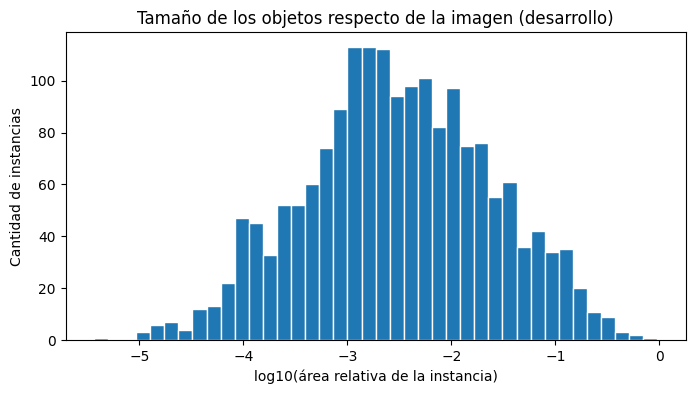


Categorías con menor área relativa mediana:
category
earring      0.00002
ring         0.00008
button       0.00010
taillight    0.00010
knob         0.00011
doorknob     0.00015
airplane     0.00024
book         0.00025
Diferencia relativa mediana entre `area` y el área de la máscara: 0.0
Diferencia relativa mediana entre `area` y el área de la caja:    0.4135
Anotaciones con `area` casi igual a la máscara (diferencia < 5 %): 1790 de 1790
Anotaciones con área de máscara <= área de caja: 1785 de 1790
Instancias chicas   (< 32² px):   54.0%
Instancias medianas (32²-96² px): 33.4%
Instancias grandes  (>= 96² px):  12.6%

Mediana de area_ratio calculada dentro de cada imagen (120 valores):
count    120.0000
mean       0.0097
std        0.0151
min        0.0001
25%        0.0019
50%        0.0046
75%        0.0101
max        0.0946


In [7]:
ann_df = pd.DataFrame(gt_ann["annotations"]).merge(
    df_img[["image_id", "width", "height"]], on="image_id")
ann_df["area_ratio"] = ann_df["area"] / (ann_df["width"] * ann_df["height"])
ann_df["category"] = ann_df["category_id"].map(VOCAB)

print("Instancias:", len(ann_df))
print(ann_df["area_ratio"].describe(percentiles=[.05, .25, .5, .75, .95]).round(4).to_string())

cortes = [0, 0.001, 0.01, 0.05, 0.2, 1.0]
etiquetas = ["<0,1 %", "0,1-1 %", "1-5 %", "5-20 %", ">20 %"]
rangos = pd.cut(ann_df["area_ratio"], bins=cortes, labels=etiquetas, include_lowest=True)
print("\nInstancias por rango de área relativa:")
print(pd.DataFrame({"n": rangos.value_counts().reindex(etiquetas),
                    "%": (rangos.value_counts(normalize=True).reindex(etiquetas) * 100).round(1)}).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log10(ann_df["area_ratio"]), bins=40, edgecolor="white")
ax.set_xlabel("log10(área relativa de la instancia)")
ax.set_ylabel("Cantidad de instancias")
ax.set_title("Tamaño de los objetos respecto de la imagen (desarrollo)")
plt.show()

print("\nCategorías con menor área relativa mediana:")
print(ann_df.groupby("category")["area_ratio"].median().nsmallest(8).round(5).to_string())

from pycocotools import mask as mask_utils

hw = {r.image_id: (r.height, r.width) for r in df_img.itertuples()}

def area_mascara(ann):
    h, w = hw[ann["image_id"]]
    rle = mask_utils.merge(mask_utils.frPyObjects(ann["segmentation"], h, w))
    return float(mask_utils.area(rle))

comp = pd.DataFrame({
    "area_campo": [ann["area"] for ann in gt_ann["annotations"]],
    "area_mascara": [area_mascara(ann) for ann in gt_ann["annotations"]],
    "area_caja": [ann["bbox"][2] * ann["bbox"][3] for ann in gt_ann["annotations"]],
})
comp["dif_rel_mascara"] = (comp["area_campo"] - comp["area_mascara"]).abs() / comp["area_mascara"].clip(lower=1)
comp["dif_rel_caja"] = (comp["area_campo"] - comp["area_caja"]).abs() / comp["area_caja"].clip(lower=1)

print("Diferencia relativa mediana entre `area` y el área de la máscara:", round(comp["dif_rel_mascara"].median(), 4))
print("Diferencia relativa mediana entre `area` y el área de la caja:   ", round(comp["dif_rel_caja"].median(), 4))
print("Anotaciones con `area` casi igual a la máscara (diferencia < 5 %):", int((comp["dif_rel_mascara"] < 0.05).sum()), "de", len(comp))
print("Anotaciones con área de máscara <= área de caja:", int((comp["area_mascara"] <= comp["area_caja"] + 1).sum()), "de", len(comp))

areas = ann_df["area"]
print("Instancias chicas   (< 32² px):  ", f"{(areas < 32**2).mean():.1%}")
print("Instancias medianas (32²-96² px):", f"{((areas >= 32**2) & (areas < 96**2)).mean():.1%}")
print("Instancias grandes  (>= 96² px): ", f"{(areas >= 96**2).mean():.1%}")

mediana_por_img = ann_df.groupby("image_id")["area_ratio"].median()
print("\nMediana de area_ratio calculada dentro de cada imagen (120 valores):")
print(mediana_por_img.describe(percentiles=[.25, .5, .75]).round(4).to_string())

**Resultado:** los objetos son muy pequeños: mediana 0,29 % de la imagen; el 71 % ocupa menos del 1 % y solo el 9,5 % el 5 % o más. `area` coincide con el área de la máscara en las 1790 anotaciones. El patrón es general (mediana por imagen 0,46 %). Según COCO, el 54 % de los objetos es chico. Los más pequeños: `earring`, `ring`, `button`, `taillight`, `knob`, `doorknob`.

**Decisiones:** resolución de entrada como parámetro a evaluar; esperar un recall limitado por objetos diminutos; `area_ratio` calculado con la máscara.

### 1.5 Frecuencia de categorías
**Pregunta:** ¿qué categorías son frecuentes y cuáles raras? **Decisión que informa:** vocabulario y métricas por categoría.

Instancias por categoría:
count    120.0
mean      14.9
std        8.9
min        3.0
25%        9.0
50%       13.0
75%       19.0
max       46.0

Categorías que aparecen en una sola imagen: 0
Categorías con 5 instancias o menos: 15
Las 10 categorías más frecuentes concentran el 19.8% de las instancias

Top 10:
          n_inst  n_imgs
category                
book          46       7
car           44       9
chair         40       8
box           40       7
wheel         37       6
shoe          31       7
pillow        31       9
curtain       29       9
person        29       9
cabinet       28       8

Bottom 10:
               n_inst  n_imgs
category                     
bird                5       3
fireplug            5       4
tennis racket       5       4
skateboard          4       4
elephant            4       4
frisbee             4       4
zebra               4       3
teddy bear          4       4
airplane            3       3
surfboard           3       3


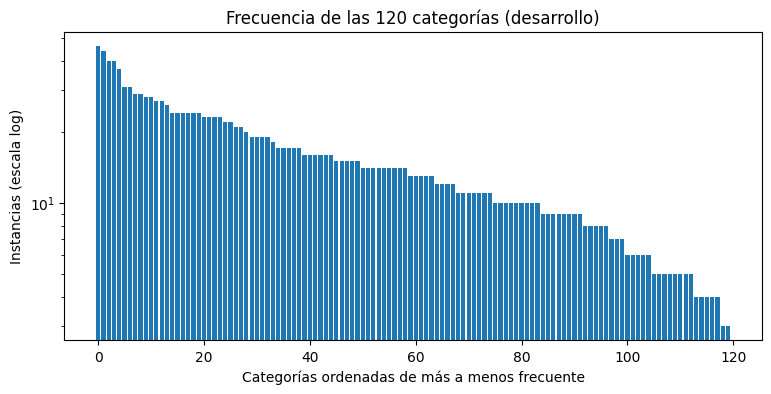

In [8]:
cat_stats = (ann_df.groupby("category")
             .agg(n_inst=("id", "count"), n_imgs=("image_id", "nunique"))
             .sort_values("n_inst", ascending=False))

print("Instancias por categoría:")
print(cat_stats["n_inst"].describe().round(1).to_string())
print("\nCategorías que aparecen en una sola imagen:", int((cat_stats["n_imgs"] == 1).sum()))
print("Categorías con 5 instancias o menos:", int((cat_stats["n_inst"] <= 5).sum()))
top10 = cat_stats["n_inst"].head(10).sum() / cat_stats["n_inst"].sum()
print(f"Las 10 categorías más frecuentes concentran el {top10:.1%} de las instancias")

print("\nTop 10:")
print(cat_stats.head(10).to_string())
print("\nBottom 10:")
print(cat_stats.tail(10).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(len(cat_stats)), cat_stats["n_inst"].values)
ax.set_yscale("log")
ax.set_xlabel("Categorías ordenadas de más a menos frecuente")
ax.set_ylabel("Instancias (escala log)")
ax.set_title("Frecuencia de las 120 categorías (desarrollo)")
plt.show()

**Resultado:** vocabulario equilibrado: entre 3 y 46 instancias por categoría (mediana 13); las 10 más frecuentes concentran solo el 19,8 %. 15 categorías tienen 5 instancias o menos.

**Decisiones:** usar las 120 categorías sin ponderar; reportar F1 global y por categoría, sin sobreinterpretar las categorías con pocas instancias.

### 1.6 Superposición entre objetos
**Pregunta:** ¿cuánto se superponen los objetos? **Decisión que informa:** umbral del NMS (supresión de duplicados) y relación `overlaps`.

El **IoU** mide cuánto se superponen dos cajas (área común / área total). El **NMS** elimina detecciones duplicadas: entre dos cajas de la misma categoría con IoU mayor al umbral, conserva la de mayor confianza.

Pares de objetos (dentro de cada imagen): 20417
Pares con alguna superposición (IoU > 0): 1903 (9.3%)
Instancias que se superponen con al menos otra: 1372 de 1790 (76.6%)

Pares por encima de cada umbral de IoU:
            misma categoría  categorías distintas
IoU >= 0,3               41                    96
IoU >= 0,5               19                    42
IoU >= 0,7                5                    29

Pares de la misma categoría con IoU >= 0,5 (los que un NMS a 0,5 suprimiría):
 image_id     category  iou
       54       banner 0.77
      108 baseball bat 0.75
       10      blanket 0.75
       71          ski 0.72
       54       banner 0.72
       35      blanket 0.69
       54       banner 0.65
       43         book 0.64
        5        plate 0.63
        5        plate 0.61


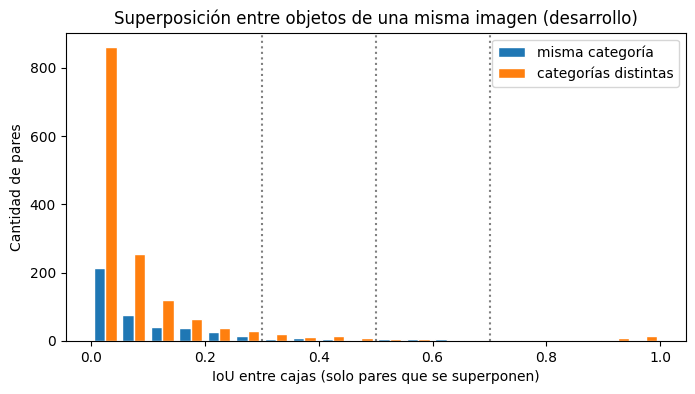

Pares: 22
 image_id           cat1             cat2  iou
       49 drinking glass              cup 1.00
      115           bowl           basket 1.00
       70            bed          blanket 0.99
       84   refrigerator          cabinet 0.99
        6        handbag         suitcase 0.99
      113            bed          blanket 0.98
      108   baseball cap   baseball glove 0.98
       62 television set computer monitor 0.98
        8 baseball glove            glove 0.97
       49 drinking glass              cup 0.97
       97       ski pole              ski 0.97
       39   baseball cap              hat 0.96
       62        cabinet           drawer 0.96
       42         button          necktie 0.95
       39   baseball cap              hat 0.95
       99           knob           handle 0.94
       62 television set computer monitor 0.93
      106       suitcase         backpack 0.92
       62        cabinet           drawer 0.92
       75        cabinet           mirror 0.92
   

In [9]:
from itertools import combinations

def iou_xywh(b1, b2):
    x1, y1, w1, h1 = b1
    x2, y2, w2, h2 = b2
    ix = max(0, min(x1 + w1, x2 + w2) - max(x1, x2))
    iy = max(0, min(y1 + h1, y2 + h2) - max(y1, y2))
    inter = ix * iy
    union = w1 * h1 + w2 * h2 - inter
    return inter / union if union > 0 else 0.0

pares = []
for img_id, g in ann_df.groupby("image_id"):
    filas = list(g[["id", "category_id", "bbox"]].itertuples(index=False))
    for a1, a2 in combinations(filas, 2):
        pares.append({
            "image_id": img_id,
            "misma_cat": a1.category_id == a2.category_id,
            "iou": iou_xywh(a1.bbox, a2.bbox),
            "id1": a1.id, "id2": a2.id,
        })
pares_df = pd.DataFrame(pares)

tocan = pares_df[pares_df["iou"] > 0]
ids_con_vecino = set(tocan["id1"]) | set(tocan["id2"])
print("Pares de objetos (dentro de cada imagen):", len(pares_df))
print(f"Pares con alguna superposición (IoU > 0): {len(tocan)} ({len(tocan)/len(pares_df):.1%})")
print(f"Instancias que se superponen con al menos otra: {len(ids_con_vecino)} de {len(ann_df)} "
      f"({len(ids_con_vecino)/len(ann_df):.1%})")

print("\nPares por encima de cada umbral de IoU:")
tabla = pd.DataFrame({
    "misma categoría": [int(((pares_df.misma_cat) & (pares_df.iou >= t)).sum()) for t in (0.3, 0.5, 0.7)],
    "categorías distintas": [int(((~pares_df.misma_cat) & (pares_df.iou >= t)).sum()) for t in (0.3, 0.5, 0.7)],
}, index=["IoU >= 0,3", "IoU >= 0,5", "IoU >= 0,7"])
print(tabla.to_string())

riesgo = pares_df[(pares_df.misma_cat) & (pares_df.iou >= 0.5)].copy()
riesgo["category"] = [VOCAB[ann_df.loc[ann_df.id == i, "category_id"].iloc[0]] for i in riesgo["id1"]]
print("\nPares de la misma categoría con IoU >= 0,5 (los que un NMS a 0,5 suprimiría):")
print(riesgo.sort_values("iou", ascending=False)[["image_id", "category", "iou"]].round(2).head(10).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist([tocan.loc[tocan.misma_cat, "iou"], tocan.loc[~tocan.misma_cat, "iou"]],
        bins=20, range=(0, 1), label=["misma categoría", "categorías distintas"], edgecolor="white")
for t in (0.3, 0.5, 0.7):
    ax.axvline(t, linestyle=":", color="gray")
ax.set_xlabel("IoU entre cajas (solo pares que se superponen)")
ax.set_ylabel("Cantidad de pares")
ax.set_title("Superposición entre objetos de una misma imagen (desarrollo)")
ax.legend()
plt.show()

casi_iguales = pares_df[(~pares_df.misma_cat) & (pares_df.iou >= 0.9)].copy()
cat_de = dict(zip(ann_df["id"], ann_df["category"]))
casi_iguales["cat1"] = casi_iguales["id1"].map(cat_de)
casi_iguales["cat2"] = casi_iguales["id2"].map(cat_de)
print("Pares:", len(casi_iguales))
print(casi_iguales.sort_values("iou", ascending=False)[["image_id", "cat1", "cat2", "iou"]].round(2).to_string(index=False))

**Resultado:** el 76,6 % de las instancias toca a otra, pero casi todos los pares tienen IoU < 0,1. Solo 19 pares de la misma categoría superan IoU 0,5 (objetos apilados: `banner`, `blanket`, `plate`). Hay 22 pares de categorías distintas casi idénticos (`cup`/`drinking glass`, `hat`/`baseball cap`, `knob`/`handle`): el mismo objeto anotado con dos categorías.

**Decisiones:** NMS **por categoría** con umbral 0,5 (pérdida máxima: 19 de 1790 objetos); `overlaps` definido con máscaras, relativo al objeto más chico.

### 1.7 Posición en la grilla 3×3
**Pregunta:** ¿dónde están los objetos y cuántos quedan cerca de un límite entre regiones? **Decisión que informa:** cálculo de `position`.

Centroides vacíos: 0

Instancias por región:
region
center           346
middle_right     237
bottom_center    236
middle_left      203
bottom_right     166
top_right        162
bottom_left      158
top_center       145
top_left         137

Instancias a menos del 5 % de un límite entre regiones: 736 de 1790 (41.1%)


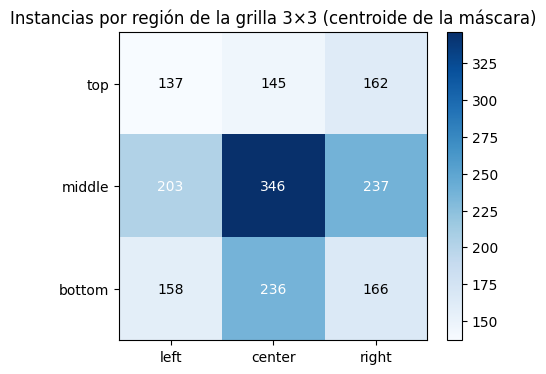

In [10]:
from pycocotools import mask as mask_utils

def centroide_mascara(ann):
    h, w = hw[ann["image_id"]]
    rle = mask_utils.merge(mask_utils.frPyObjects(ann["segmentation"], h, w))
    m = mask_utils.decode(rle)
    ys, xs = np.nonzero(m)
    if len(xs) == 0:                      # máscara vacía (no debería pasar en el ground truth)
        return np.nan, np.nan
    return xs.mean() / w, ys.mean() / h   # normalizado a [0, 1]

FILAS = ["top", "middle", "bottom"]
COLS = ["left", "center", "right"]

def region(cx, cy):
    col = COLS[min(int(cx * 3), 2)]
    fila = FILAS[min(int(cy * 3), 2)]
    return "center" if (fila, col) == ("middle", "center") else f"{fila}_{col}"

cents = [centroide_mascara(ann) for ann in gt_ann["annotations"]]
pos_df = pd.DataFrame(cents, columns=["cx", "cy"])
pos_df["region"] = [region(cx, cy) for cx, cy in cents]

# distancia al límite entre tercios más cercano (en fracción de la imagen)
def dist_limite(v):
    return min(abs(v - 1/3), abs(v - 2/3))
pos_df["ambiguo"] = [min(dist_limite(cx), dist_limite(cy)) < 0.05 for cx, cy in cents]

print("Centroides vacíos:", int(pos_df["cx"].isna().sum()))
print("\nInstancias por región:")
print(pos_df["region"].value_counts().to_string())
print(f"\nInstancias a menos del 5 % de un límite entre regiones: {pos_df['ambiguo'].sum()} "
      f"de {len(pos_df)} ({pos_df['ambiguo'].mean():.1%})")

grilla = np.zeros((3, 3), dtype=int)
for cx, cy in cents:
    grilla[min(int(cy * 3), 2), min(int(cx * 3), 2)] += 1

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(grilla, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, grilla[i, j], ha="center", va="center",
                color="white" if grilla[i, j] > grilla.max() / 2 else "black")
ax.set_xticks(range(3)); ax.set_xticklabels(COLS)
ax.set_yticks(range(3)); ax.set_yticklabels(FILAS)
ax.set_title("Instancias por región de la grilla 3×3 (centroide de la máscara)")
fig.colorbar(im, ax=ax)
plt.show()

**Resultado:** las 9 regiones tienen objetos (137 a 346), con sesgo moderado al centro (`center`: 19,3 % frente a 11,1 % uniforme). El 41,1 % de los centroides está a menos del 5 % de un límite (36 % esperable por azar): su región depende de pocos píxeles.

**Decisiones:** `position` por centroide de la máscara (`[x, y]`) con la imagen dividida en tercios; "siempre `center`" (~19 %) como referencia trivial.

### Resumen del EDA

| Pregunta | Hallazgo | Decisión |
|---|---|---|
| ¿Datos consistentes? (1.2) | Coherentes; 7,3 de 120 categorías verificables por imagen | Precisión + cobertura; priorizar recall |
| ¿Objetos por imagen? (1.3) | Mediana 10,5, máximo 66 | No limitar detecciones |
| ¿Tamaño? (1.4) | Mediana 0,29 % del área; 54 % chicos (COCO) | Resolución como parámetro; `area_ratio` por máscara |
| ¿Frecuencia? (1.5) | 3 a 46 instancias por categoría | 120 categorías sin ponderar |
| ¿Superposición? (1.6) | 19 pares misma categoría IoU ≥ 0,5; 22 pares de categorías cercanas | NMS por categoría a 0,5; `overlaps` por máscaras |
| ¿Posición? (1.7) | Sesgo moderado al centro | `position` por centroide en tercios |

# 2. Detección open-vocabulary
Usamos **OWLv2** (`google/owlv2-base-patch16-ensemble`), que busca objetos a partir de sus nombres en texto, sin reentrenarlo. La función de detección recibe **solo la imagen**.

### 2.1 Detectar y guardar
OWLv2 compara miles de cajas candidatas con los 120 nombres (consulta "a photo of a {categoría}", la plantilla habitual de los modelos derivados de CLIP) y asigna a cada caja la categoría de mayor confianza. Guardamos todas las detecciones con confianza ≥ 0,01: así se pueden probar umbrales y NMS sin volver a usar la GPU.

preprocessor_config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  620MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

Resolución de entrada del detector: SizeDict(height=960, width=960, longest_edge=None, shortest_edge=None, max_height=None, max_width=None)
Tiempo total: 101 s | 0.84 s por imagen
Imágenes: 120 | detecciones guardadas por imagen (media): 571


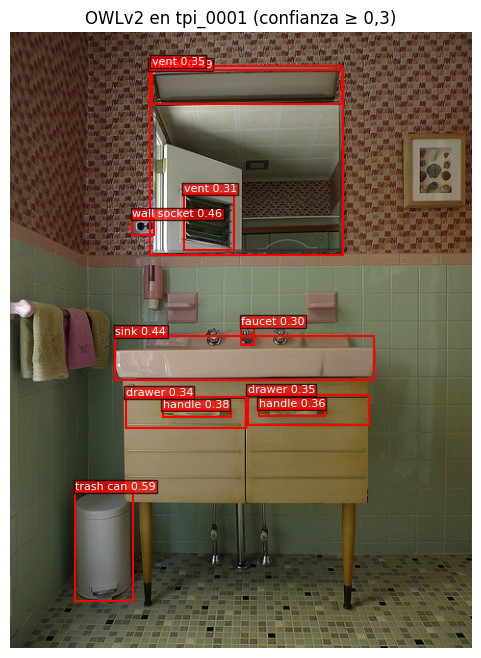

In [11]:
import torch, time, pickle
import matplotlib.patches as patches
from transformers import Owlv2Processor, Owlv2ForObjectDetection

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODELO_DET = "google/owlv2-base-patch16-ensemble"
PLANTILLA = "a photo of a {}"
SCORE_MIN_CACHE = 0.01

processor = Owlv2Processor.from_pretrained(MODELO_DET)
detector = Owlv2ForObjectDetection.from_pretrained(MODELO_DET).to(DEVICE).eval()

print("Resolución de entrada del detector:", processor.image_processor.size)

CAT_IDS = sorted(VOCAB)
TEXTOS = [PLANTILLA.format(VOCAB[c]) for c in CAT_IDS]

@torch.no_grad()
def detectar(ruta):
    """Recibe SOLO la ruta de la imagen. Devuelve cajas xyxy con categoría y confianza."""
    img = Image.open(ruta).convert("RGB")
    w, h = img.size
    entrada = processor(text=[TEXTOS], images=img, return_tensors="pt").to(DEVICE)
    salida = detector(**entrada)

    scores, idx = salida.logits[0].sigmoid().max(-1)       # mejor categoría de cada caja
    cx, cy, bw, bh = salida.pred_boxes[0].unbind(-1)        # normalizadas a la imagen cuadrada rellenada
    S = max(w, h)                                           # OWLv2 rellena la imagen hasta hacerla cuadrada
    x1 = ((cx - bw / 2) * S).clamp(0, w); y1 = ((cy - bh / 2) * S).clamp(0, h)
    x2 = ((cx + bw / 2) * S).clamp(0, w); y2 = ((cy + bh / 2) * S).clamp(0, h)

    keep = (scores >= SCORE_MIN_CACHE) & (x2 - x1 > 1) & (y2 - y1 > 1)
    return [{"category_id": CAT_IDS[int(i)], "score": float(s),
             "bbox": [float(a), float(b), float(c), float(d)]}
            for s, i, a, b, c, d in zip(scores[keep], idx[keep], x1[keep], y1[keep], x2[keep], y2[keep])]

# ---------- Detectar en las 120 imágenes de desarrollo (con caché) ----------
CACHE_DET = OUT / "det_owlv2_base_dev.pkl"
if CACHE_DET.exists():
    det_dev = pickle.load(open(CACHE_DET, "rb"))
    print("Detecciones cargadas desde", CACHE_DET)
else:
    det_dev, t0 = {}, time.time()
    for f in sorted(PATHS["dev_images"].glob("*.jpg")):
        det_dev[f.stem] = detectar(f)
    pickle.dump(det_dev, open(CACHE_DET, "wb"))
    print(f"Tiempo total: {time.time() - t0:.0f} s | {(time.time() - t0) / len(det_dev):.2f} s por imagen")

n_det = [len(v) for v in det_dev.values()]
print("Imágenes:", len(det_dev), "| detecciones guardadas por imagen (media):", round(np.mean(n_det)))

CONFIG.update({"detector": MODELO_DET, "plantilla": PLANTILLA, "score_min_cache": SCORE_MIN_CACHE})

# ---------- Ejemplo visual: tpi_0001 ----------
ejemplo = sorted([d for d in det_dev["tpi_0001"] if d["score"] >= 0.3], key=lambda d: -d["score"])[:15]
img = Image.open(PATHS["dev_images"] / "tpi_0001.jpg")
fig, ax = plt.subplots(figsize=(6, 8))
ax.imshow(img); ax.axis("off")
for d in ejemplo:
    x1, y1, x2, y2 = d["bbox"]
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="red", linewidth=1.5))
    ax.text(x1, y1 - 2, f"{VOCAB[d['category_id']]} {d['score']:.2f}", color="white", fontsize=8,
            bbox=dict(facecolor="red", alpha=0.7, pad=1))
ax.set_title("OWLv2 en tpi_0001 (confianza ≥ 0,3)")
plt.show()

### 2.2 Umbral de confianza y línea base
Filtramos por confianza, aplicamos NMS por categoría (IoU 0,5) y medimos el F1 de cajas para varios umbrales. El umbral se elige y se mide sobre las mismas imágenes, así que el resultado puede ser algo optimista para el test.

In [ ]:
import torchvision

def postprocesar(dets, umbral, nms_iou=0.5, max_det=300):
    """Filtra por confianza, aplica NMS por categoría y devuelve objetos en formato SceneJSON (sin máscara)."""
    d = [x for x in dets if x["score"] >= umbral]
    if not d:
        return []
    cajas = torch.tensor([x["bbox"] for x in d], dtype=torch.float32)
    scores = torch.tensor([x["score"] for x in d])
    cats = torch.tensor([x["category_id"] for x in d])
    keep = torchvision.ops.batched_nms(cajas, scores, cats, nms_iou)[:max_det]   # NMS por categoría
    return [{"id": f"obj_{i + 1:03d}", "category_id": d[k]["category_id"],
             "confidence": d[k]["score"], "bbox": d[k]["bbox"]}
            for i, k in enumerate(keep.tolist())]

# ---------- Barrido de umbrales ----------
UMBRALES = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4]
filas = []
for u in UMBRALES:
    preds = {k: postprocesar(v, u) for k, v in det_dev.items()}
    r = evaluar(preds, tipos=("bbox",))["resumen"].loc["bbox"]
    filas.append({"umbral": u, "f1": r["f1"], "precision": r["precision"], "recall": r["recall"],
                  "cobertura": r["cobertura"], "f1_medio_img": r["f1_medio_por_imagen"],
                  "pred_por_img": np.mean([len(p) for p in preds.values()])})
barrido = pd.DataFrame(filas)
print(barrido.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
for col in ["f1", "precision", "recall"]:
    ax.plot(barrido["umbral"], barrido[col], marker="o", label=col)
ax.axhline(0.4, linestyle=":", color="gray"); ax.axhline(0.5, linestyle=":", color="gray")
ax.set_xlabel("Umbral de confianza"); ax.set_ylabel("Valor")
ax.set_title("OWLv2 base: métricas de cajas según el umbral (desarrollo)")
ax.legend(); plt.show()

# ---------- Línea base con el mejor umbral ----------
UMBRAL_BASE = float(barrido.loc[barrido["f1"].idxmax(), "umbral"])
preds_base = {k: postprocesar(v, UMBRAL_BASE) for k, v in det_dev.items()}
res_base = evaluar(preds_base, tipos=("bbox",))
print(f"\nLínea base (umbral {UMBRAL_BASE}, NMS 0,5 por categoría):")
mostrar(res_base)

CONFIG.update({"score_thr": UMBRAL_BASE, "nms_iou": 0.5, "max_det": 300})

# ---------- Categorías con peor F1 (al menos 5 instancias anotadas) ----------
pc = res_base["por_categoria"]
pc = pc[pc["tp"] + pc["fn"] >= 5].sort_values("f1")
print("\nCategorías con peor F1:")
print(pc[["category", "f1", "precision", "recall", "tp", "fp", "fn"]].head(10).round(2).to_string(index=False))

**Resultado:** el F1 forma una meseta entre los umbrales 0,15 y 0,25. Con **umbral 0,20: F1 de cajas = 0,646** (precisión 0,73, recall 0,58), por encima del umbral de promoción. La cobertura es del 46 %: más de la mitad de las predicciones cae en categorías no verificadas. Se producen 25 predicciones por imagen frente a ~15 objetos anotados. Peores categorías: `person` (recall 0,03), objetos chicos o repetidos (`book`, `shoe`, `doorknob`) y confusiones (`streetlight`).

### 2.3 Análisis de error: baja detección de personas
`person` detecta 1 de 29 personas. Para cada persona anotada buscamos la detección que mejor la cubre (IoU ≥ 0,5), primero entre las que superan el umbral y luego entre todas las guardadas.

In [ ]:
from collections import Counter

def iou_xyxy(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

PERSON = next(c for c, n in VOCAB.items() if n == "person")
etiquetas = Counter()
for k, g in gt_index.items():
    dets = [d for d in det_dev[k] if d["score"] >= UMBRAL_BASE]
    for o in g["objetos"]:
        if o["category_id"] != PERSON:
            continue
        mejor = max(dets, key=lambda d: iou_xyxy(d["bbox"], o["bbox"]), default=None)
        if mejor is None or iou_xyxy(mejor["bbox"], o["bbox"]) < 0.5:
            etiquetas["(ninguna caja con IoU ≥ 0,5)"] += 1
        else:
            etiquetas[VOCAB[mejor["category_id"]]] += 1
print("Categoría asignada a la caja que mejor cubre cada persona anotada:")
for cat, n in etiquetas.most_common():
    print(f"  {cat}: {n}")

etiquetas_todas = Counter()
for k, g in gt_index.items():
    for o in g["objetos"]:
        if o["category_id"] != PERSON:
            continue
        mejor = max(det_dev[k], key=lambda d: iou_xyxy(d["bbox"], o["bbox"]), default=None)
        if mejor is None or iou_xyxy(mejor["bbox"], o["bbox"]) < 0.5:
            etiquetas_todas["(ninguna caja con IoU ≥ 0,5)"] += 1
        else:
            etiquetas_todas[f"{VOCAB[mejor['category_id']]} (conf. {mejor['score']:.2f})"] += 1
print("Usando todas las detecciones guardadas (≥ 0,01):")
for cat, n in etiquetas_todas.most_common():
    print(f"  {cat}: {n}")

| Detecciones consideradas | Cubierta por caja `person` | Cubierta por otra categoría | Sin caja |
|---|---|---|---|
| Superan el umbral (≥ 0,20) | 1 | 9 (5 `shirt`) | 19 |
| Todas las guardadas (≥ 0,01) | **28** | 0 | 1 |

**Conclusión:** la hipótesis inicial (las prendas "le roban" la etiqueta a la persona) era incorrecta. El detector encuentra y nombra bien a 28 de 29 personas, pero con confianzas de 0,01 a 0,20. El problema es la **calibración**: las confianzas de OWLv2 no son comparables entre categorías, y un umbral único perjudica a algunas. Queda como experimento (consigna 7): variar la plantilla de texto.

### Justificación de las decisiones de detección

| Decisión | Elección | Justificación |
|---|---|---|
| Detector | OWLv2 base | Open-vocabulary, evaluado sobre LVIS, disponible en `transformers`; 0,45 s por imagen en T4 |
| Vocabulario | Las 120 categorías de `categories.csv`, con "a photo of a {categoría}" | Vocabulario oficial; plantilla estándar de CLIP |
| Umbral de confianza | 0,20 | Máximo F1 en desarrollo, dentro de una meseta estable (0,15–0,25) |
| Resolución de entrada | La fija de OWLv2 (impresa en 2.1); la imagen se rellena hasta hacerla cuadrada | Resolución con la que fue entrenado el modelo |
| Supresión de duplicados | NMS por categoría, IoU 0,5 | EDA 1.6: solo 19 pares reales lo superan; por categoría para no borrar objetos con dos etiquetas |

# 3. Segmentación de instancias con SAM2
Cada caja de la línea base es la pista ("prompt") para **SAM2.1** (`facebook/sam2.1-hiera-large`), que devuelve la silueta del objeto. SAM2 no decide qué es el objeto: la categoría la pone el detector. Las máscaras se guardan como RLE no comprimido, column-major.

### 3.1 Segmentar y guardar
Se pasan todas las cajas de cada imagen juntas a SAM2, que devuelve una máscara por caja (`multimask_output=False`). Si una máscara sale vacía, se reemplaza por el rectángulo de la caja, porque el schema exige `area_ratio > 0`.

In [ ]:
import transformers
print("Versión de transformers:", transformers.__version__)
from transformers import Sam2Processor, Sam2Model

MODELO_SEG = "facebook/sam2.1-hiera-large"
sam_proc = Sam2Processor.from_pretrained(MODELO_SEG)
sam = Sam2Model.from_pretrained(MODELO_SEG).to(DEVICE).eval()

@torch.no_grad()
def segmentar(ruta, objetos):
    """Recibe la ruta de la imagen y sus objetos detectados (con 'bbox'). Agrega 'mask' a cada objeto."""
    if not objetos:
        return [], 0
    img = Image.open(ruta).convert("RGB")
    w, h = img.size
    entrada = sam_proc(images=img, input_boxes=[[o["bbox"] for o in objetos]], return_tensors="pt").to(DEVICE)
    salida = sam(**entrada, multimask_output=False)
    masks = sam_proc.post_process_masks(salida.pred_masks.cpu(), entrada["original_sizes"].cpu())[0]
    masks = masks[:, 0].numpy().astype(np.uint8)            # (cantidad de cajas, alto, ancho)

    resultado, vacias = [], 0
    for o, m in zip(objetos, masks):
        if m.sum() == 0:                                     # máscara vacía -> rectángulo de la caja
            x1, y1, x2, y2 = [int(round(v)) for v in o["bbox"]]
            m = np.zeros((h, w), dtype=np.uint8)
            m[y1:max(y2, y1 + 1), x1:max(x2, x1 + 1)] = 1
            vacias += 1
        resultado.append({**o, "mask": mascara_a_rle_scene(m)})
    return resultado, vacias

# ---------- Segmentar las 120 imágenes (con caché) ----------
CACHE_SEG = OUT / f"seg_sam2L_dev_u{UMBRAL_BASE}.pkl"
if CACHE_SEG.exists():
    seg_dev, n_vacias = pickle.load(open(CACHE_SEG, "rb"))
    print("Máscaras cargadas desde", CACHE_SEG)
else:
    seg_dev, n_vacias, t0 = {}, 0, time.time()
    for k, objs in preds_base.items():
        seg_dev[k], v = segmentar(PATHS["dev_images"] / f"{k}.jpg", objs)
        n_vacias += v
    pickle.dump((seg_dev, n_vacias), open(CACHE_SEG, "wb"))
    print(f"Tiempo total: {time.time() - t0:.0f} s | {(time.time() - t0) / len(seg_dev):.2f} s por imagen")

n_masks = sum(len(v) for v in seg_dev.values())
print(f"Máscaras: {n_masks} | vacías reemplazadas por la caja: {n_vacias}")
CONFIG.update({"segmentador": MODELO_SEG, "multimask_output": False, "mascara_vacia": "rectángulo de la caja"})

# ---------- Ejemplo visual: tpi_0001 ----------
img = np.array(Image.open(PATHS["dev_images"] / "tpi_0001.jpg").convert("RGB"))
fig, ax = plt.subplots(figsize=(6, 8))
ax.imshow(img); ax.axis("off")
rng = np.random.default_rng(SEED)
for o in seg_dev["tpi_0001"]:
    m = mask_utils.decode(rle_scene_a_rle(o["mask"])).astype(bool)
    capa = np.zeros((*m.shape, 4)); capa[m] = [*rng.random(3), 0.5]
    ax.imshow(capa)
    ax.text(o["bbox"][0], o["bbox"][1] - 2, VOCAB[o["category_id"]], color="white", fontsize=8,
            bbox=dict(facecolor="black", alpha=0.6, pad=1))
ax.set_title("SAM2 en tpi_0001 (cajas de la línea base)")
plt.show()

### 3.2 Evaluación de máscaras
La tabla cruzada separa los errores: caja correcta y máscara incorrecta = error de SAM2; caja incorrecta = error del detector, que SAM2 no puede corregir.

In [ ]:
res_seg = evaluar(seg_dev)
print("Detector OWLv2 + SAM2.1 large:")
mostrar(res_seg)

# ---------- ¿De dónde vienen los errores de máscara? ----------
det = res_seg["detalle"]
caja = det[det.tipo == "bbox"].set_index(["image_id", "pred_id"])["resultado"].rename("caja")
masc = det[det.tipo == "mask"].set_index(["image_id", "pred_id"])["resultado"].rename("mascara")
cruce = pd.concat([caja, masc], axis=1)
print("\nResultado de cada predicción en cajas (filas) y en máscaras (columnas):")
print(pd.crosstab(cruce["caja"], cruce["mascara"], margins=True, margins_name="total"))

tp_caja = (cruce["caja"] == "tp").sum()
tp_ambas = ((cruce["caja"] == "tp") & (cruce["mascara"] == "tp")).sum()
print(f"\nDe {tp_caja} cajas correctas, SAM2 produjo una máscara correcta en {tp_ambas} ({tp_ambas / tp_caja:.1%})")

**Resultado:** **F1 de máscaras = 0,617** (precisión 0,70, recall 0,55), apenas por debajo del de cajas (0,646), sin máscaras vacías. De las 1035 cajas correctas, SAM2 segmentó bien 951 (91,9 %); en cambio, 349 predicciones fallan ya en la caja. La mayor parte de la pérdida está en el **detector**, donde conviene concentrar las mejoras.

### 3.3 Propiedades derivadas y relaciones
A partir de cada máscara:

| Propiedad | Cálculo |
|---|---|
| `area_ratio` | píxeles de la máscara / (ancho × alto) |
| `centroid` | promedio de las coordenadas `[x, y]` de la máscara |
| `position` | región 3×3 del centroide (imagen dividida en tercios) |
| `size` | `small` (< 1 %), `medium` (1 %–10 %), `large` (≥ 10 %) |
| `color` | color dominante: mediana RGB dentro de la máscara, asignada a un nombre básico |

Relaciones entre pares: `left_of`/`right_of` y `above`/`below` comparando centroides; `overlaps` si las máscaras comparten al menos el 10 % del objeto más chico. Cada par se guarda una vez (la inversa se deduce). Si una imagen superara las 20 000 relaciones del schema, se calculan solo entre los objetos más confiables.

**Pendiente de confirmar con la cátedra:** los umbrales de `size`, que el enunciado no define.

In [ ]:
UMBRALES_SIZE = (0.01, 0.10)      # small < 1 % ; medium < 10 % ; large >= 10 %
UMBRAL_OVERLAP = 0.10             # fracción del objeto más chico
MAX_REL = 20000                   # límite del schema
FILAS, COLS = ["top", "middle", "bottom"], ["left", "center", "right"]

import colorsys

def color_dominante(img, m):
    """Mediana RGB dentro de la máscara, asignada a un nombre de color básico."""
    r, g, b = np.median(img[m], axis=0) / 255
    h, s, v = colorsys.rgb_to_hsv(r, g, b)
    if v < 0.2:
        return "black"
    if s < 0.15:
        return "white" if v > 0.8 else "gray"
    hue = h * 360
    if hue < 15 or hue >= 345: return "red"
    if hue < 45: return "brown" if v < 0.6 else "orange"
    if hue < 70: return "yellow"
    if hue < 170: return "green"
    if hue < 260: return "blue"
    if hue < 300: return "purple"
    return "pink"

def region(cx, cy, w, h):
    col = COLS[min(int(3 * cx / w), 2)]
    fila = FILAS[min(int(3 * cy / h), 2)]
    return "center" if (fila, col) == ("middle", "center") else f"{fila}_{col}"

def tamano(ar):
    return "small" if ar < UMBRALES_SIZE[0] else ("medium" if ar < UMBRALES_SIZE[1] else "large")

def cajas_se_tocan(a, b):
    return a[0] < b[2] and b[0] < a[2] and a[1] < b[3] and b[1] < a[3]

def construir_escena(objs, img):
    """Agrega propiedades a cada objeto y calcula las relaciones. No usa anotaciones."""
    h, w = img.shape[:2]
    mascaras, objetos = [], []
    for o in objs:
        m = mask_utils.decode(rle_scene_a_rle(o["mask"])).astype(bool)
        ys, xs = np.nonzero(m)
        cx, cy = float(xs.mean()), float(ys.mean())
        ar = len(xs) / (h * w)
        objetos.append({**o, "area_ratio": ar, "centroid": [cx, cy],
                        "position": region(cx, cy, w, h), "size": tamano(ar),
                        "color": color_dominante(img, m)})
        mascaras.append(m)

    # si hay demasiados pares, se limitan las relaciones a los objetos más confiables
    orden = sorted(range(len(objetos)), key=lambda i: -objetos[i]["confidence"])
    n_max = len(orden)
    while n_max * (n_max - 1) > MAX_REL - 1000:     # ~2 relaciones por par + margen para overlaps
        n_max -= 1
    idx = orden[:n_max]

    relaciones = []
    for a_pos, i in enumerate(idx):
        for j in idx[a_pos + 1:]:
            A, B = objetos[i], objetos[j]
            relaciones.append({"subject": A["id"], "object": B["id"],
                               "predicate": "left_of" if A["centroid"][0] < B["centroid"][0] else "right_of"})
            relaciones.append({"subject": A["id"], "object": B["id"],
                               "predicate": "above" if A["centroid"][1] < B["centroid"][1] else "below"})
            if cajas_se_tocan(A["bbox"], B["bbox"]):
                inter = np.logical_and(mascaras[i], mascaras[j]).sum()
                menor = min(mascaras[i].sum(), mascaras[j].sum())
                if inter / menor >= UMBRAL_OVERLAP:
                    relaciones.append({"subject": A["id"], "object": B["id"], "predicate": "overlaps"})
    return objetos, relaciones

# ---------- Aplicar a las 120 imágenes de desarrollo ----------
escenas_dev = {}
for k, objs in seg_dev.items():
    img = np.array(Image.open(PATHS["dev_images"] / f"{k}.jpg").convert("RGB"))   # tamaño leído de la imagen
    h, w = img.shape[:2]
    objetos, relaciones = construir_escena(objs, img)
    escenas_dev[k] = {"image": {"id": k, "width": w, "height": h},
                      "objects": objetos, "relations": relaciones}

CONFIG.update({"umbrales_size": UMBRALES_SIZE, "umbral_overlap": UMBRAL_OVERLAP})

# ---------- Resumen ----------
todos = [o for e in escenas_dev.values() for o in e["objects"]]
n_rel = [len(e["relations"]) for e in escenas_dev.values()]
print("Objetos:", len(todos), "| area_ratio mínimo:", f"{min(o['area_ratio'] for o in todos):.6f}")
print("\nTamaño:\n" + pd.Series([o["size"] for o in todos]).value_counts().to_string())
print("\nColor:\n" + pd.Series([o["color"] for o in todos]).value_counts().to_string())
print("\nPosición:\n" + pd.Series([o["position"] for o in todos]).value_counts().to_string())
print("\nRelaciones por imagen: media", round(np.mean(n_rel)), "| máximo", max(n_rel), f"(límite {MAX_REL})")
print("Relaciones 'overlaps' en total:",
      sum(r["predicate"] == "overlaps" for e in escenas_dev.values() for r in e["relations"]))

**Resultado:** 3051 objetos, todos con `area_ratio > 0`. Tamaños: 2111 `small` (69 %), 813 `medium` y 127 `large`, coherente con el EDA. Las 9 posiciones están representadas. Colores: predominan `gray` (701), `black` (609) y `brown` (443), propio de escenas de interior; los 11 colores aparecen. Relaciones: media 852 por imagen, máximo 5880 (por debajo del límite de 20 000), con 1330 relaciones `overlaps` en total.

**Limitación:** el color no se puede validar, porque las anotaciones no lo incluyen.

# 4. Representación estructurada de la escena
Convertimos cada escena al formato oficial del SceneJSON y lo validamos de dos formas:
1. **Contra `scene_schema.json`** (campos obligatorios, tipos y valores permitidos).
2. **Consistencia interna**, que el schema no verifica: ids de objeto únicos, relaciones que apuntan a objetos existentes, máscara del tamaño de la imagen, RLE que suma ancho × alto, `area_ratio` coherente con la máscara, y caja y centroide dentro de la imagen.

Además verificamos que el evaluador dé el mismo F1 sobre el SceneJSON final que sobre las predicciones originales, es decir, que el armado no pierde ni altera información.

In [ ]:
import jsonschema

SCHEMA = json.load(open(PATHS["schema"]))
validador = jsonschema.Draft202012Validator(SCHEMA)

def a_scene_json(escena):
    """Escena interna -> SceneJSON oficial, solo con tipos estándar de Python."""
    img = escena["image"]
    objetos = [{
        "id": str(o["id"]),
        "category_id": int(o["category_id"]),
        "confidence": float(o["confidence"]),
        "bbox": [round(float(v), 2) for v in o["bbox"]],
        "mask": {"size": [int(v) for v in o["mask"]["size"]], "counts": [int(c) for c in o["mask"]["counts"]]},
        "centroid": [round(float(v), 2) for v in o["centroid"]],
        "area_ratio": float(o["area_ratio"]),
        "position": o["position"],
        "size": o["size"],
        "color": o["color"],
    } for o in escena["objects"]]
    return {"image": {"id": str(img["id"]), "width": int(img["width"]), "height": int(img["height"])},
            "objects": objetos,
            "relations": [dict(r) for r in escena["relations"]]}

def problemas_consistencia(sj):
    """Chequeos que el schema no cubre. Devuelve una lista de problemas (vacía = OK)."""
    h, w = sj["image"]["height"], sj["image"]["width"]
    p, ids = [], [o["id"] for o in sj["objects"]]
    if len(ids) != len(set(ids)):
        p.append("ids de objeto repetidos")
    ids = set(ids)
    for o in sj["objects"]:
        m = o["mask"]
        if m["size"] != [h, w]:
            p.append(f"{o['id']}: máscara de tamaño {m['size']}")
        elif sum(m["counts"]) != h * w:
            p.append(f"{o['id']}: el RLE no suma alto × ancho")
        else:
            px = sum(m["counts"][1::2])                      # los conteos impares son píxeles del objeto
            if abs(px / (h * w) - o["area_ratio"]) > 1e-6:
                p.append(f"{o['id']}: area_ratio no coincide con la máscara")
        x1, y1, x2, y2 = o["bbox"]
        if not (-1 <= x1 < x2 <= w + 1 and -1 <= y1 < y2 <= h + 1):
            p.append(f"{o['id']}: caja fuera de la imagen")
        cx, cy = o["centroid"]
        if not (0 <= cx <= w and 0 <= cy <= h):
            p.append(f"{o['id']}: centroide fuera de la imagen")
    for r in sj["relations"]:
        if r["subject"] not in ids or r["object"] not in ids:
            p.append(f"relación con objeto inexistente: {r}")
    return p

# ---------- Armar y validar las 120 escenas de desarrollo ----------
scene_dev = {k: a_scene_json(e) for k, e in escenas_dev.items()}
errores_schema = {k: [e.message for e in validador.iter_errors(sj)] for k, sj in scene_dev.items()}
errores_schema = {k: v for k, v in errores_schema.items() if v}
errores_consist = {k: problemas_consistencia(sj) for k, sj in scene_dev.items()}
errores_consist = {k: v for k, v in errores_consist.items() if v}

print("Escenas:", len(scene_dev))
print("Escenas con errores de schema:", len(errores_schema))
print("Escenas con errores de consistencia:", len(errores_consist))
for k, v in list({**errores_schema, **errores_consist}.items())[:3]:
    print(" ", k, "->", v[:3])

# ---------- Tamaño del JSON ----------
kb = [len(json.dumps(sj)) / 1024 for sj in scene_dev.values()]
print(f"\nTamaño por escena: media {np.mean(kb):.0f} KB | máximo {max(kb):.0f} KB")

# ---------- El armado no altera las predicciones ----------
print("\nEvaluación sobre el SceneJSON final:")
mostrar(evaluar(scene_dev))

# ---------- Ejemplo de SceneJSON (tpi_0001) ----------
ej = scene_dev["tpi_0001"]
muestra = {
    "image": ej["image"],
    "objects": [{**o, "mask": {"size": o["mask"]["size"],
                               "counts": o["mask"]["counts"][:6] + ["..."]}}
                for o in ej["objects"][:2]],
    "relations": ej["relations"][:5],
}
print(f"\nEjemplo de SceneJSON (tpi_0001): {len(ej['objects'])} objetos y {len(ej['relations'])} relaciones.")
print("Se muestran 2 objetos y 5 relaciones; los 'counts' de la máscara están recortados.")
print(json.dumps(muestra, indent=2, ensure_ascii=False))

# 5. Trazabilidad de la pipeline
La pipeline completa queda en una sola función, `procesar_imagen(ruta)`, que recibe **solo la ruta de la imagen** (nunca anotaciones) y ejecuta en orden:

`carga → detección → postproceso (umbral + NMS) → segmentación → propiedades y relaciones → SceneJSON → validación`

Cada etapa se registra en `trazas.jsonl` con:

| Campo | Contenido |
|---|---|
| `run_id`, `image_id`, `etapa` | Qué ejecución, qué imagen y qué etapa |
| `params` | Parámetros usados (modelo, umbral, NMS, etc.) |
| `n_entrada`, `n_salida` | Objetos que entran y salen (en `validacion`, `n_salida` = cantidad de errores) |
| `segundos`, `estado`, `error` | Tiempo, `ok` / `error` / `invalido` y mensaje del error |

Si una etapa falla, la traza registra dónde y la ejecución sigue con la imagen siguiente. Es la misma función que se usará sobre las imágenes de test (sección 8).

In [18]:
import datetime

ARCHIVO_TRAZAS = OUT / "trazas.jsonl"
RUN_ID = datetime.datetime.now().strftime("%Y%m%d-%H%M%S")

class Traza:
    """Registra cada etapa del procesamiento de una imagen."""
    def __init__(self, image_id):
        self.image_id, self.registros = image_id, []

    def etapa(self, nombre, funcion, params=None, n_entrada=None, contar=len):
        reg = {"run_id": RUN_ID, "image_id": self.image_id, "etapa": nombre,
               "params": params or {}, "n_entrada": n_entrada}
        t0 = time.time()
        try:
            resultado = funcion()
            reg.update(estado="ok", n_salida=contar(resultado))
            return resultado
        except Exception as e:
            reg.update(estado="error", error=f"{type(e).__name__}: {e}")
            raise
        finally:
            reg["segundos"] = round(time.time() - t0, 3)
            self.registros.append(reg)

def validar(sj):
    return [e.message for e in validador.iter_errors(sj)] + problemas_consistencia(sj)

def procesar_imagen(ruta, umbral=None):
    """Pipeline completa para UNA imagen. Recibe solo la ruta: no usa anotaciones."""
    umbral = UMBRAL_BASE if umbral is None else umbral
    ruta = Path(ruta)
    tr = Traza(ruta.stem)
    sj = None
    try:
        img = tr.etapa("carga", lambda: np.array(Image.open(ruta).convert("RGB")),
                       contar=lambda a: f"{a.shape[1]}x{a.shape[0]}")
        dets = tr.etapa("deteccion", lambda: detectar(ruta),
                        params={"modelo": MODELO_DET, "plantilla": PLANTILLA, "score_min": SCORE_MIN_CACHE})
        objs = tr.etapa("postproceso", lambda: postprocesar(dets, umbral),
                        params={"umbral": umbral, "nms_iou": 0.5, "max_det": 300}, n_entrada=len(dets))
        objs_m, vacias = tr.etapa("segmentacion", lambda: segmentar(ruta, objs),
                                  params={"modelo": MODELO_SEG}, n_entrada=len(objs),
                                  contar=lambda r: len(r[0]))
        tr.registros[-1]["params"]["mascaras_vacias"] = vacias
        objetos, relaciones = tr.etapa("propiedades", lambda: construir_escena(objs_m, img),
                                       params={"umbrales_size": UMBRALES_SIZE, "umbral_overlap": UMBRAL_OVERLAP},
                                       n_entrada=len(objs_m), contar=lambda r: len(r[1]))
        h, w = img.shape[:2]
        sj = tr.etapa("scene_json",
                      lambda: a_scene_json({"image": {"id": ruta.stem, "width": w, "height": h},
                                            "objects": objetos, "relations": relaciones}),
                      n_entrada=len(objetos), contar=lambda s: len(s["objects"]))
        errores = tr.etapa("validacion", lambda: validar(sj), n_entrada=len(sj["objects"]))
        if errores:
            tr.registros[-1].update(estado="invalido", error=errores[:3])
    except Exception:
        sj = None          # la traza ya registró en qué etapa falló
    with open(ARCHIVO_TRAZAS, "a") as f:
        for r in tr.registros:
            f.write(json.dumps(r, default=str) + "\n")
    return sj, tr.registros

# ---------- Pipeline completa sobre las 120 imágenes de desarrollo ----------
ARCHIVO_TRAZAS.write_text("")
scene_e2e, t0 = {}, time.time()
for f in sorted(PATHS["dev_images"].glob("*.jpg")):
    scene_e2e[f.stem], _ = procesar_imagen(f)
print(f"Tiempo total: {time.time() - t0:.0f} s | {(time.time() - t0) / len(scene_e2e):.2f} s por imagen")

# ---------- Análisis de las trazas ----------
trazas = pd.read_json(ARCHIVO_TRAZAS, lines=True)
trazas["n_salida_num"] = pd.to_numeric(trazas["n_salida"], errors="coerce")
resumen_etapas = trazas.groupby("etapa", sort=False).agg(
    seg_medio=("segundos", "mean"), seg_total=("segundos", "sum"),
    salida_total=("n_salida_num", "sum"),
    no_ok=("estado", lambda s: int((s != "ok").sum())))
print("\nResumen por etapa (120 imágenes):")
print(resumen_etapas.round(2).to_string())

print("\nEjemplo de traza (tpi_0001):")
cols = ["etapa", "n_entrada", "n_salida", "segundos", "estado"]
print(trazas[trazas.image_id == "tpi_0001"][cols].to_string(index=False))

# ---------- Reproducibilidad: la pipeline unificada debe dar las mismas métricas ----------
fallidas = [k for k, v in scene_e2e.items() if v is None]
print("\nImágenes con error:", fallidas)
print("Evaluación de la pipeline completa:")
mostrar(evaluar({k: v for k, v in scene_e2e.items() if v is not None}))

Tiempo total: 196 s | 1.63 s por imagen

Resumen por etapa (120 imágenes):
              seg_medio  seg_total  salida_total  no_ok
etapa                                                  
carga              0.01       0.85           0.0      0
deteccion          0.52      62.22       68461.0      0
postproceso        0.00       0.08        3051.0      0
segmentacion       0.97     116.02        3051.0      0
propiedades        0.08       9.65      102274.0      0
scene_json         0.00       0.05        3051.0      0
validacion         0.06       7.16           0.0      0

Ejemplo de traza (tpi_0001):
       etapa  n_entrada n_salida  segundos estado
       carga        NaN  480x640     0.011     ok
   deteccion        NaN      352     0.557     ok
 postproceso      352.0       17     0.000     ok
segmentacion       17.0       17     0.868     ok
 propiedades       17.0      288     0.056     ok
  scene_json       17.0       17     0.000     ok
  validacion       17.0        0     0.03

# 6. Preguntas y respuestas sobre la escena
Arquitectura común a ambos modos: **consulta estructurada → validación → ejecución determinista sobre el SceneJSON → respuesta normalizada**. La única fuente de información es el SceneJSON predicho.

### 6.1 Modo determinista
La consulta se arma con los campos de la cátedra (`type`, `class_en`); en las relaciones, el predicado se toma de frases fijas del texto ("por encima de" → `above`, etc.), sin LLM.

| Operación | Respuesta normalizada | Cómo se resuelve |
|---|---|---|
| `existence` | `yes` / `no` | ¿Hay algún objeto de la clase? |
| `count` | entero | Cantidad de objetos de la clase |
| `position` | una de 9 regiones | `position` de la instancia |
| `size` | `small` / `medium` / `large` | `size` de la instancia |
| `relation` | `yes` / `no` | Se consulta `relations` del SceneJSON |
| `description` | texto | Plantilla con los objetos más frecuentes y confiables |

**Casos especiales:**
- Varias instancias de la clase pedida → se usa la más confiable y la `confidence` se divide por la cantidad de instancias.
- Ninguna instancia en posición, tamaño o relación → `unsupported` ("información insuficiente"), `confidence` 0.
- Consulta inválida (operación o clase desconocida) → `unsupported`.

**`confidence`:** la del objeto usado (en relaciones, la menor de los dos); en conteo, el promedio; en "no" o conteo 0, 0,5 fija, porque el detector pierde el 42 % de los objetos. Son reglas explicables, no probabilidades calibradas.

In [19]:
from collections import Counter

NOMBRE_A_ID = {nombre: int(cid) for cid, nombre in VOCAB.items()}
OPERACIONES = {"count": 1, "existence": 1, "position": 1, "size": 1, "relation": 2, "description": 0}
FRASES_REL = {"por encima de": "above", "por debajo de": "below",
              "a la izquierda de": "left_of", "a la derecha de": "right_of"}
INVERSA = {"above": "below", "below": "above", "left_of": "right_of", "right_of": "left_of"}
EJE = {"above": "v", "below": "v", "left_of": "h", "right_of": "h"}
CONF_NEGATIVA = 0.5

# ---------- Consulta estructurada ----------
def consulta_desde_campos(q):
    """Modo determinista: arma la consulta con los campos estructurados de la cátedra."""
    consulta = {"operacion": q["type"], "clases": list(q.get("class_en") or []), "relacion": None}
    if q["type"] == "relation":
        texto = q["question"].lower()
        consulta["relacion"] = next((p for frase, p in FRASES_REL.items() if frase in texto), None)
    return consulta

def validar_consulta(c):
    op = c.get("operacion")
    if op not in OPERACIONES:
        return f"operación no soportada ({op})"
    if len(c.get("clases") or []) != OPERACIONES[op]:
        return f"'{op}' requiere {OPERACIONES[op]} clase(s)"
    fuera = [x for x in c["clases"] if x not in NOMBRE_A_ID]
    if fuera:
        return f"clase fuera del vocabulario {fuera}"
    if op == "relation" and c.get("relacion") not in ("above", "below", "left_of", "right_of", "overlaps"):
        return f"relación no soportada ({c.get('relacion')})"
    return None

# ---------- Motor determinista ----------
def instancias(sj, clase):
    cid = NOMBRE_A_ID[clase]
    return sorted([o for o in sj["objects"] if o["category_id"] == cid], key=lambda o: -o["confidence"])

def cumple_relacion(sj, a, b, pred):
    """Busca la relación en `relations`; si el par no está guardado, compara centroides."""
    for r in sj["relations"]:
        par = (r["subject"], r["object"])
        if pred == "overlaps":
            if r["predicate"] == "overlaps" and set(par) == {a["id"], b["id"]}:
                return True
            continue
        if r["predicate"] == "overlaps" or EJE[r["predicate"]] != EJE[pred]:
            continue
        if par == (a["id"], b["id"]):
            return r["predicate"] == pred
        if par == (b["id"], a["id"]):
            return INVERSA[r["predicate"]] == pred
    if pred == "overlaps":
        return False
    i = 1 if EJE[pred] == "v" else 0
    a_menor = a["centroid"][i] < b["centroid"][i]
    return a_menor if pred in ("above", "left_of") else not a_menor

def no_soportada(motivo):
    return {"answer": f"Información insuficiente: {motivo}.", "normalized_answer": "unsupported",
            "evidence": [], "confidence": 0.0}

def salida(answer, normalizada, evidencia, conf):
    return {"answer": answer, "normalized_answer": normalizada,
            "evidence": [o["id"] for o in evidencia], "confidence": round(float(conf), 3)}

def describir(sj):
    objs = sorted(sj["objects"], key=lambda o: -o["confidence"])
    if not objs:
        texto = "No se detectaron objetos en la escena."
        return {"answer": texto, "normalized_answer": texto, "evidence": [], "confidence": CONF_NEGATIVA}
    conteo = Counter(VOCAB[o["category_id"]] for o in objs)
    frecuentes = ", ".join(f"{n} {c}" for c, n in conteo.most_common(5))
    top = objs[:3]
    detalle = "; ".join(f"{VOCAB[o['category_id']]} ({o['position']}, {o['size']}, {o['color']})" for o in top)
    texto = (f"Se detectaron {len(objs)} objetos de {len(conteo)} categorías. "
             f"Las más frecuentes: {frecuentes}. Los más confiables: {detalle}.")
    return salida(texto, texto, top, np.mean([o["confidence"] for o in top]))

def ejecutar(consulta, sj):
    """Ejecuta una consulta estructurada sobre el SceneJSON. Es el mismo motor para ambos modos."""
    error = validar_consulta(consulta)
    if error:
        return no_soportada(error)
    op, clases = consulta["operacion"], consulta["clases"]
    if op == "description":
        return describir(sj)

    inst = [instancias(sj, c) for c in clases]
    if op == "count":
        n = len(inst[0])
        conf = np.mean([o["confidence"] for o in inst[0]]) if n else CONF_NEGATIVA
        return salida(f"Se detectaron {n} instancia(s) de '{clases[0]}'.", n, inst[0], conf)
    if op == "existence":
        if inst[0]:
            return salida(f"Sí: se detectaron {len(inst[0])} instancia(s) de '{clases[0]}'.",
                          "yes", inst[0], inst[0][0]["confidence"])
        return salida(f"No se detectó ninguna instancia de '{clases[0]}'.", "no", [], CONF_NEGATIVA)

    faltan = [c for c, lista in zip(clases, inst) if not lista]
    if faltan:
        return no_soportada(f"no se detectó ninguna instancia de {faltan}")
    elegidos = [lista[0] for lista in inst]
    conf = min(o["confidence"] / len(lista) for o, lista in zip(elegidos, inst))
    nota = "" if all(len(l) == 1 for l in inst) else " (había varias instancias; se usó la más confiable)"

    if op in ("position", "size"):
        valor = elegidos[0][op]
        campo = "está en la zona" if op == "position" else "tiene tamaño"
        return salida(f"La instancia de '{clases[0]}' {campo} {valor}{nota}.", valor, elegidos, conf)
    si = cumple_relacion(sj, elegidos[0], elegidos[1], consulta["relacion"])
    texto = (f"{'Sí' if si else 'No'}: '{clases[0]}' {'' if si else 'no '}cumple "
             f"'{consulta['relacion']}' respecto de '{clases[1]}'{nota}.")
    return salida(texto, "yes" if si else "no", elegidos, conf)

def responder(q, sj, armar_consulta=consulta_desde_campos):
    consulta = armar_consulta(q)
    return {"question_id": q["question_id"], "type": q["type"], "question": q["question"],
            **ejecutar(consulta, sj)}, consulta

# ---------- Responder las 60 consignas del benchmark ----------
preguntas = q_df.assign(image_id=q_df["image_file"].str.replace(".jpg", "", regex=False)).to_dict("records")
questions_det, consultas_det = {}, {}
for q in preguntas:
    r, c = responder(q, scene_e2e[q["image_id"]])
    questions_det.setdefault(q["image_id"], []).append(r)
    consultas_det[q["question_id"]] = c

# ---------- Validación contra el schema (con el campo questions incluido) ----------
errores_q = sum(len(list(validador.iter_errors({**scene_e2e[k], "questions": v}))) for k, v in questions_det.items())
print("Imágenes con respuestas:", len(questions_det), "| errores de schema:", errores_q)

tabla_det = pd.DataFrame([r for v in questions_det.values() for r in v])
print("\nRespuestas por tipo:")
print(tabla_det.groupby("type")["normalized_answer"].agg(
    total="count", unsupported=lambda s: int((s == "unsupported").sum())).to_string())
print("\nPreguntas cerradas:")
cerradas = tabla_det[tabla_det.type != "description"]
print(cerradas[["question_id", "type", "normalized_answer", "confidence"]].to_string(index=False))
print("\nEjemplo de descripción:", tabla_det[tabla_det.type == "description"].iloc[0]["answer"])

Imágenes con respuestas: 20 | errores de schema: 0

Respuestas por tipo:
             total  unsupported
type                           
count           10            0
description     20            0
existence       10            0
position         5            0
relation        10            2
size             5            2

Preguntas cerradas:
question_id      type normalized_answer  confidence
   DEV-1-Q1     count                 0       0.500
   DEV-1-Q2 existence               yes       0.457
   DEV-2-Q1     count                 2       0.415
   DEV-2-Q2 existence               yes       0.714
   DEV-3-Q1     count                 2       0.443
   DEV-3-Q2 existence                no       0.500
   DEV-4-Q1     count                 2       0.264
   DEV-4-Q2 existence                no       0.500
   DEV-6-Q1     count                 3       0.454
   DEV-6-Q2 existence                no       0.500
   DEV-5-Q1     count                 1       0.530
   DEV-5-Q2  relation     

In [20]:
# ---------- Respuestas de referencia: mismas reglas aplicadas a las anotaciones (SOLO para evaluar) ----------
def escena_gt(k):
    img = np.array(Image.open(PATHS["dev_images"] / f"{k}.jpg").convert("RGB"))
    objetos, rel = construir_escena(gt_como_pred(k), img)
    h, w = img.shape[:2]
    return a_scene_json({"image": {"id": k, "width": w, "height": h}, "objects": objetos, "relations": rel})

gt_escenas = {k: escena_gt(k) for k in questions_det}

# ---------- Fidelidad: ¿la respuesta coincide con lo que dice el SceneJSON? ----------
def es_fiel(r, consulta, sj):
    objs = {o["id"]: o for o in sj["objects"]}
    if any(e not in objs for e in r["evidence"]):
        return False
    if r["normalized_answer"] == "unsupported" or consulta["operacion"] == "description":
        return True
    ev = [objs[e] for e in r["evidence"]]
    ids_clase = [NOMBRE_A_ID[c] for c in consulta["clases"]]
    if any(o["category_id"] not in ids_clase for o in ev):
        return False
    op = consulta["operacion"]
    if op == "count":
        return r["normalized_answer"] == len(ev) == len(instancias(sj, consulta["clases"][0]))
    if op == "existence":
        return (r["normalized_answer"] == "yes") == (len(instancias(sj, consulta["clases"][0])) > 0)
    if op in ("position", "size"):
        return r["normalized_answer"] == ev[0][op]
    return (r["normalized_answer"] == "yes") == cumple_relacion(sj, ev[0], ev[1], consulta["relacion"])

# ---------- Exactitud: comparación con la respuesta de referencia ----------
filas = []
for q in preguntas:
    if q["type"] == "description":
        continue
    pred = next(r for r in questions_det[q["image_id"]] if r["question_id"] == q["question_id"])
    consulta = consultas_det[q["question_id"]]
    ref = ejecutar(consulta, gt_escenas[q["image_id"]])
    n_gt = [len(instancias(gt_escenas[q["image_id"]], c)) for c in consulta["clases"]]
    filas.append({"question_id": q["question_id"], "type": q["type"], "clases": consulta["clases"],
                  "pred": pred["normalized_answer"], "ref": ref["normalized_answer"],
                  "correcta": pred["normalized_answer"] == ref["normalized_answer"],
                  "fiel": es_fiel(pred, consulta, scene_e2e[q["image_id"]]),
                  "varias_en_gt": q["type"] in ("position", "size", "relation") and max(n_gt) > 1})
eval_det = pd.DataFrame(filas)

print("Modo determinista: fidelidad y exactitud por tipo")
print(eval_det.groupby("type").agg(n=("correcta", "size"), exactitud=("correcta", "mean"),
                                   fidelidad=("fiel", "mean"),
                                   unsupported=("pred", lambda s: int((s == "unsupported").sum())),
                                   ambiguas_en_gt=("varias_en_gt", "sum")).round(2).to_string())
print(f"\nTotal: exactitud {eval_det.correcta.mean():.2f} | fidelidad {eval_det.fiel.mean():.2f}")
print("\nRespuestas incorrectas:")
print(eval_det[~eval_det.correcta][["question_id", "type", "clases", "pred", "ref", "varias_en_gt"]].to_string(index=False))

Modo determinista: fidelidad y exactitud por tipo
            n  exactitud  fidelidad  unsupported  ambiguas_en_gt
type                                                            
count      10        0.5        1.0            0               0
existence  10        0.9        1.0            0               0
position    5        1.0        1.0            0               0
relation   10        0.8        1.0            2               0
size        5        0.6        1.0            2               0

Total: exactitud 0.75 | fidelidad 1.00

Respuestas incorrectas:
question_id      type          clases        pred   ref  varias_en_gt
   DEV-1-Q1     count      [doorknob]           0     2         False
   DEV-4-Q1     count      [trousers]           2     4         False
   DEV-6-Q1     count       [handbag]           3     2         False
   DEV-5-Q1     count          [fork]           1     3         False
   DEV-8-Q1     count         [glove]           1     2         False
  DEV-23-Q

### 6.2 Modo con LLM
LLM liviano (`Qwen/Qwen2.5-3B-Instruct`) recibe **solo el texto de la pregunta** y produce la consulta estructurada (`interpreted_query`). La consulta se **valida** (operación soportada, clases del vocabulario; nombres casi exactos se corrigen con `difflib`) y la ejecuta **el mismo motor de la 6.1**. El LLM solo traduce y redacta:
- **Interpretación:** pregunta en español → `{"operacion", "clases", "relacion"}`. Si la pregunta no se puede responder con las operaciones soportadas, devuelve `"unsupported"`.
- **Verbalización:** redacta una oración a partir del resultado del motor, sin agregar información.
- **Descripción:** 2 o 3 oraciones a partir de un resumen del SceneJSON (conteos y objetos principales con posición, tamaño y color).

El LLM no ve la imagen ni los campos estructurados de la cátedra, y no calcula respuestas: conteos, filtros y comparaciones los resuelve el código.

**Evaluación:** (1) interpretación: ¿la consulta del LLM coincide con la del modo determinista?; (2) exactitud frente a la referencia; (3) fidelidad: ¿la respuesta, la verbalización y la descripción coinciden con el SceneJSON, sin objetos inventados?

In [21]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import re, difflib

MODELO_LLM = "Qwen/Qwen2.5-3B-Instruct"
DEVICE_LLM = "cuda:1" if torch.cuda.device_count() > 1 else DEVICE
if "llm" not in globals():      # cargar una sola vez, aunque la celda se ejecute de nuevo
    tok_llm = AutoTokenizer.from_pretrained(MODELO_LLM)
    llm = AutoModelForCausalLM.from_pretrained(MODELO_LLM, torch_dtype=torch.float16).to(DEVICE_LLM).eval()

@torch.no_grad()
def generar(sistema, usuario, max_tokens=200):
    mensajes = [{"role": "system", "content": sistema}, {"role": "user", "content": usuario}]
    entrada = tok_llm.apply_chat_template(mensajes, add_generation_prompt=True,
                                          return_tensors="pt", return_dict=True).to(DEVICE_LLM)
    out = llm.generate(**entrada, max_new_tokens=max_tokens, do_sample=False,
                       pad_token_id=tok_llm.eos_token_id)
    n_entrada = entrada["input_ids"].shape[1]
    return tok_llm.decode(out[0, n_entrada:], skip_special_tokens=True).strip()

# ---------- 1) Interpretación: texto -> consulta ----------
SISTEMA_INTERPRETE = f"""Convertís preguntas en español sobre una imagen en una consulta JSON. No respondés la pregunta: solo la traducís.
Devolvé SOLO un JSON: {{"operacion": ..., "clases": [...], "relacion": ...}}
- "operacion": "existence", "count", "position", "size", "relation", "description", o "unsupported" si no se puede responder con esas operaciones.
- "clases": nombres en inglés copiados EXACTAMENTE de esta lista: {", ".join(sorted(NOMBRE_A_ID))}. Si el objeto no está en la lista, la operación es "unsupported".
- "relacion": solo en "relation": "above" (por encima de), "below" (por debajo de), "left_of" (a la izquierda de), "right_of" (a la derecha de), "overlaps" (superpuesto con). Si no, null.
- "existence", "count", "position" y "size" usan 1 clase; "relation", 2 clases en el orden de la pregunta; "description", ninguna.
Ejemplos:
Pregunta: ¿Hay algún paraguas en la imagen?
{{"operacion": "existence", "clases": ["umbrella"], "relacion": null}}
Pregunta: ¿Cuántos almohadones aparecen?
{{"operacion": "count", "clases": ["pillow"], "relacion": null}}
Pregunta: ¿El almohadón está por encima del sofá?
{{"operacion": "relation", "clases": ["pillow", "sofa"], "relacion": "above"}}
Pregunta: ¿De qué humor está la persona?
{{"operacion": "unsupported", "clases": [], "relacion": null}}"""

def consulta_desde_llm(q):
    """Modo LLM: recibe SOLO q['question']."""
    crudo = generar(SISTEMA_INTERPRETE, f"Pregunta: {q['question']}", 80)
    m = re.search(r"\{.*\}", crudo, re.S)
    try:
        c = json.loads(m.group(0))
    except Exception:
        return {"operacion": None, "clases": [], "relacion": None, "crudo": crudo}
    clases = []
    for x in c.get("clases") or []:
        x = str(x).strip().lower()
        if x not in NOMBRE_A_ID:
            parecido = difflib.get_close_matches(x, list(NOMBRE_A_ID), n=1, cutoff=0.85)
            x = parecido[0] if parecido else x
        clases.append(x)
    return {"operacion": c.get("operacion"), "clases": clases, "relacion": c.get("relacion"), "crudo": crudo}

# ---------- 2) Verbalización del resultado del motor ----------
SISTEMA_VERBAL = ("Redactás en español UNA oración breve que responda la pregunta usando SOLO el resultado dado. "
                  "No agregues información. Incluí literalmente el valor del resultado. "
                  "Si el resultado es 'unsupported', decí que no hay información suficiente.")

def verbalizar(q, r):
    return generar(SISTEMA_VERBAL, f"Pregunta: {q['question']}\nResultado: {r['normalized_answer']}\n"
                                   f"Detalle del motor: {r['answer']}", 60)

# ---------- 3) Descripción a partir de un resumen del SceneJSON ----------
SISTEMA_DESC = ("Describís una escena en 2 o 3 oraciones en español usando SOLO los datos del JSON. "
                "No inventes objetos, colores ni posiciones. Escribí los nombres de los objetos tal como aparecen (en inglés).")

def resumen_escena(sj, max_obj=12):
    objs = sorted(sj["objects"], key=lambda o: -o["confidence"])[:max_obj]
    return json.dumps({
        "total_objetos": len(sj["objects"]),
        "conteo_por_categoria": dict(Counter(VOCAB[o["category_id"]] for o in sj["objects"]).most_common(8)),
        "objetos_principales": [{"categoria": VOCAB[o["category_id"]], "posicion": o["position"],
                                 "tamano": o["size"], "color": o["color"]} for o in objs]}, ensure_ascii=False)

def categorias_mencionadas(texto):
    t = texto.lower()
    return {c for c in NOMBRE_A_ID if re.search(rf"\b{re.escape(c)}s?\b", t)}

def describir_llm(sj):
    texto = generar(SISTEMA_DESC, resumen_escena(sj), 160)
    nombres = categorias_mencionadas(texto)
    evidencia = [o for o in sorted(sj["objects"], key=lambda o: -o["confidence"])[:12]
                 if VOCAB[o["category_id"]] in nombres]
    return texto, evidencia

# ---------- 4) Respuesta completa en modo LLM ----------
def responder_llm(q, sj):
    consulta = consulta_desde_llm(q)
    error = validar_consulta(consulta)
    if consulta.get("operacion") == "description" and error is None:
        texto, ev = describir_llm(sj)
        r = {"answer": texto, "normalized_answer": texto, "evidence": [o["id"] for o in ev],
             "confidence": round(float(np.mean([o["confidence"] for o in ev])) if ev else CONF_NEGATIVA, 3)}
    else:
        r = ejecutar(consulta, sj)
        r["answer"] = verbalizar(q, r) or r["answer"]
    iq = {"operacion": consulta.get("operacion"), "clases": consulta.get("clases"),
          "relacion": consulta.get("relacion"), "valida": error is None, "error": error,
          "salida_llm": consulta.get("crudo")}
    return {"question_id": q["question_id"], "type": q["type"], "question": q["question"],
            **r, "interpreted_query": iq}, consulta

# ---------- Responder las 60 consignas ----------
t0 = time.time()
questions_llm, consultas_llm = {}, {}
for q in preguntas:
    r, c = responder_llm(q, scene_e2e[q["image_id"]])
    questions_llm.setdefault(q["image_id"], []).append(r)
    consultas_llm[q["question_id"]] = c
print(f"Tiempo: {time.time() - t0:.0f} s para {len(preguntas)} consignas")

errores_q = sum(len(list(validador.iter_errors({**scene_e2e[k], "questions_llm": v})))
                for k, v in questions_llm.items())
print("Errores de schema con questions_llm:", errores_q)
CONFIG.update({"llm": MODELO_LLM, "llm_decodificacion": "greedy"})

# ---------- Preguntas fuera del benchmark: manejo de casos difíciles ----------
extra = ["¿De qué color son los ojos de la persona?",      # fuera de alcance
         "¿Cuántos unicornios hay en la imagen?",           # objeto fuera del vocabulario
         "¿Qué hay cerca?",                                 # ambigua
         "¿Hay un lavabo en la imagen?"]                    # normal (sink)
print("\nPreguntas fuera del benchmark (imagen tpi_0001):")
for i, texto in enumerate(extra):
    r, c = responder_llm({"question_id": f"EXTRA-{i}", "type": "?", "question": texto}, scene_e2e["tpi_0001"])
    print(f"- {texto}\n  consulta: {r['interpreted_query']['operacion']} {r['interpreted_query']['clases']} "
          f"| válida: {r['interpreted_query']['valida']} | respuesta: {r['normalized_answer']}\n  texto: {r['answer']}")

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Tiempo: 196 s para 60 consignas
Errores de schema con questions_llm: 0

Preguntas fuera del benchmark (imagen tpi_0001):
- ¿De qué color son los ojos de la persona?
  consulta: unsupported [] | válida: False | respuesta: unsupported
  texto: unsupported
- ¿Cuántos unicornios hay en la imagen?
  consulta: count ['unicorn'] | válida: False | respuesta: unsupported
  texto: unsupported
- ¿Qué hay cerca?
  consulta: relation [] | válida: False | respuesta: unsupported
  texto: no hay información suficiente
- ¿Hay un lavabo en la imagen?
  consulta: existence ['toilet'] | válida: True | respuesta: no
  texto: no


In [22]:
filas = []
for q in preguntas:
    qid, k = q["question_id"], q["image_id"]
    r = next(x for x in questions_llm[k] if x["question_id"] == qid)
    det = next(x for x in questions_det[k] if x["question_id"] == qid)
    c_llm, c_det = consultas_llm[qid], consultas_det[qid]
    interpreta_bien = (c_llm.get("operacion") == c_det["operacion"] and c_llm.get("clases") == c_det["clases"]
                       and (c_det["operacion"] != "relation" or c_llm.get("relacion") == c_det["relacion"]))
    fila = {"question_id": qid, "type": q["type"], "interpreta_bien": interpreta_bien}
    if q["type"] == "description":
        inventadas = categorias_mencionadas(r["answer"]) - {VOCAB[o["category_id"]] for o in scene_e2e[k]["objects"]}
        fila.update(descripcion_fiel=not inventadas, inventadas=sorted(inventadas))
    else:
        ref = ejecutar(c_det, gt_escenas[k])["normalized_answer"]
        norm = r["normalized_answer"]
        valor = {"yes": "sí", "no": "no"}.get(norm, str(norm)).lower()
        fila.update(pred=norm, det=det["normalized_answer"], ref=ref,
                    correcta=norm == ref, igual_que_det=norm == det["normalized_answer"],
                    fiel=es_fiel(r, c_llm, scene_e2e[k]) if r["interpreted_query"]["valida"] else True,
                    verbal_fiel=valor in r["answer"].lower())
    filas.append(fila)
eval_llm = pd.DataFrame(filas)
cerr = eval_llm[eval_llm.type != "description"]

print("Modo LLM por tipo de pregunta:")
print(cerr.groupby("type").agg(n=("correcta", "size"), interpretacion=("interpreta_bien", "mean"),
                               exactitud=("correcta", "mean"), igual_que_det=("igual_que_det", "mean"),
                               fidelidad=("fiel", "mean"), verbalizacion=("verbal_fiel", "mean")).round(2).to_string())
print(f"\nTotal (40 cerradas): interpretación {cerr.interpreta_bien.mean():.2f} | exactitud {cerr.correcta.mean():.2f} "
      f"(determinista: {eval_det.correcta.mean():.2f}) | fidelidad {cerr.fiel.mean():.2f}")

desc = eval_llm[eval_llm.type == "description"]
print(f"Descripciones: {int(desc.interpreta_bien.sum())}/20 interpretadas como descripción | "
      f"{int(desc.descripcion_fiel.sum())}/20 sin objetos inventados")

print("\nInterpretaciones distintas a la determinista:")
for qid in eval_llm[~eval_llm.interpreta_bien].question_id:
    print(f"  {qid}: LLM {consultas_llm[qid].get('operacion')} {consultas_llm[qid].get('clases')} "
          f"{consultas_llm[qid].get('relacion')} | correcto {consultas_det[qid]['operacion']} "
          f"{consultas_det[qid]['clases']} {consultas_det[qid]['relacion']}")

print("\nEjemplo de descripción con LLM:\n ", questions_llm["tpi_0001"][0]["answer"])

Modo LLM por tipo de pregunta:
            n  interpretacion exactitud igual_que_det fidelidad verbalizacion
type                                                                         
count      10             0.6       0.3           0.6       1.0           1.0
existence  10             0.9       0.8           0.9       1.0           0.5
position    5             0.8       0.8           0.8       1.0           1.0
relation   10             0.7       0.5           0.7       1.0           0.8
size        5             0.8       0.6           1.0       1.0           0.8

Total (40 cerradas): interpretación 0.75 | exactitud 0.57 (determinista: 0.75) | fidelidad 1.00
Descripciones: 20/20 interpretadas como descripción | 20/20 sin objetos inventados

Interpretaciones distintas a la determinista:
  DEV-3-Q1: LLM count ['jar'] None | correcto count ['vase'] None
  DEV-4-Q1: LLM count ['short pants'] None | correcto count ['trousers'] None
  DEV-6-Q1: LLM count ['backpack'] None | correcto c

**Resultado:** las 60 consignas se responden con SceneJSON válidos (205 s). Sobre las 40 preguntas cerradas, el LLM interpreta correctamente el 75 % (la consulta coincide con la del modo determinista) y la exactitud es **0,57**, frente a 0,75 del modo determinista. La fidelidad es 1,00: el motor ejecuta fielmente lo que el LLM interpreta.

**Análisis de errores:** en las 10 interpretaciones fallidas, la operación y la relación son correctas; el error está siempre en la clase. En 5 casos el LLM produce un nombre fuera del vocabulario (`glasses`, `bag`, `plant`, `table_surf`, `mango`), que la validación rechaza como `unsupported` (error seguro). En otros 5 elige una categoría válida pero incorrecta (`jar` por `vase`, `backpack` por `handbag`, `watch` por `clock`, entre otros), lo que produce respuestas incorrectas sin aviso.

**Casos difíciles:** las preguntas fuera de alcance, con objetos fuera del vocabulario o ambiguas se rechazan correctamente como `unsupported`. Pero "lavabo" se tradujo como `toilet` en lugar de `sink`.

**Limitaciones detectadas:** las descripciones usan nombres en español pese a la instrucción, por lo que la verificación automática de objetos inventados no es concluyente; además, la descripción revisada contiene un error de posición (ubica el tacho de basura arriba cuando el JSON dice `bottom_left`). La verbalización es a veces mínima ("no").

Este resultado es la **línea base del modo LLM**; las mejoras se evalúan en la consigna 7.

# 7. Evaluación y experimentación

### 7.1 Métricas por etapa y end-to-end
Resumen de las métricas de cada etapa, todas calculadas sobre las 120 imágenes de desarrollo (las preguntas, sobre las 20 del benchmark).

In [23]:
filas = [
    ("Detección (cajas)", "F1 / precisión / recall", f"{res_base['resumen'].loc['bbox','f1']:.3f} / "
     f"{res_base['resumen'].loc['bbox','precision']:.3f} / {res_base['resumen'].loc['bbox','recall']:.3f}",
     f"cobertura {res_base['resumen'].loc['bbox','cobertura']:.2f}"),
    ("Segmentación (máscaras)", "F1 / precisión / recall", f"{res_seg['resumen'].loc['mask','f1']:.3f} / "
     f"{res_seg['resumen'].loc['mask','precision']:.3f} / {res_seg['resumen'].loc['mask','recall']:.3f}",
     "91,9 % de las cajas correctas con máscara correcta"),
    ("SceneJSON", "escenas válidas (schema + consistencia)",
     f"{120 - len(errores_schema) - len(errores_consist)}/120", "F1 idéntico antes y después del armado"),
    ("Preguntas, modo determinista", "exactitud / fidelidad",
     f"{eval_det.correcta.mean():.2f} / {eval_det.fiel.mean():.2f}", "40 preguntas cerradas"),
    ("Preguntas, modo LLM", "interpretación / exactitud / fidelidad",
     f"{cerr.interpreta_bien.mean():.2f} / {cerr.correcta.mean():.2f} / {cerr.fiel.mean():.2f}", "40 preguntas cerradas"),
    ("Pipeline completa", "tiempo por imagen / imágenes con error",
     f"{resumen_etapas['seg_total'].sum() / 120:.2f} s / {len(fallidas)}", "SAM2: 59 % del tiempo"),
]
print(pd.DataFrame(filas, columns=["Etapa", "Métrica", "Valor", "Nota"]).to_string(index=False))

                       Etapa                                 Métrica                 Valor                                               Nota
           Detección (cajas)                 F1 / precisión / recall 0.646 / 0.732 / 0.578                                     cobertura 0.46
     Segmentación (máscaras)                 F1 / precisión / recall 0.617 / 0.701 / 0.551 91,9 % de las cajas correctas con máscara correcta
                   SceneJSON escenas válidas (schema + consistencia)               120/120             F1 idéntico antes y después del armado
Preguntas, modo determinista                   exactitud / fidelidad           0.75 / 1.00                              40 preguntas cerradas
         Preguntas, modo LLM  interpretación / exactitud / fidelidad    0.75 / 0.57 / 1.00                              40 preguntas cerradas
           Pipeline completa  tiempo por imagen / imágenes con error            1.63 s / 0                              SAM2: 59 % del tiempo


### 7.2 Experimento controlado: selección de la categoría en el modo LLM
**Hipótesis:** el LLM elige mal la categoría porque debe escogerla de una lista de 120 nombres. Si traduce libremente el objeto al inglés y la categoría se elige por similitud de significado, la interpretación y la exactitud deberían mejorar.

| | Línea base (6.2) | Alternativa |
|---|---|---|
| Quién elige la categoría | El LLM, de una lista de 120 nombres | El código, por similitud de texto (codificador de OWLv2) entre la traducción libre del LLM y las 120 categorías |
| Sin categoría parecida | Nombre inválido → `unsupported` | Similitud < 0,80 → `unsupported` |
| Todo lo demás | Igual: mismo LLM, mismas reglas, mismo motor, mismas preguntas | Igual |

El umbral de 0,80 se fijó de antemano, sin ajustarlo con el benchmark.

In [24]:
# ---------- Embeddings de texto con el codificador de OWLv2 (ya cargado) ----------
NOMBRES_VOCAB = sorted(NOMBRE_A_ID)

@torch.no_grad()
def emb_texto(textos):
    t = processor.tokenizer([PLANTILLA.format(x) for x in textos], padding="max_length",
                            truncation=True, return_tensors="pt").to(DEVICE)
    e = detector.owlv2.get_text_features(input_ids=t["input_ids"], attention_mask=t["attention_mask"])
    if not torch.is_tensor(e):                      # transformers nuevo: devuelve un objeto con campos
        e = e.text_embeds if getattr(e, "text_embeds", None) is not None else e.pooler_output
    return torch.nn.functional.normalize(e, dim=-1)

EMB_VOCAB = emb_texto(NOMBRES_VOCAB)
UMBRAL_SIM = 0.80

def mapear_clase(nombre):
    """Devuelve (categoría del vocabulario o el nombre original, similitud)."""
    nombre = str(nombre).strip().lower()
    if nombre in NOMBRE_A_ID:
        return nombre, 1.0
    sims = (emb_texto([nombre]) @ EMB_VOCAB.T)[0]
    i = int(sims.argmax())
    return (NOMBRES_VOCAB[i] if sims[i] >= UMBRAL_SIM else nombre), float(sims[i])

# ---------- Interpretación con traducción libre (sin la lista de categorías) ----------
SISTEMA_LIBRE = SISTEMA_INTERPRETE.split("- \"clases\":")[0] + \
"""- "clases": el nombre del objeto traducido al inglés, en singular, como se diría naturalmente (por ejemplo "vase", "glasses", "doorknob").
- "relacion": solo en "relation": "above" (por encima de), "below" (por debajo de), "left_of" (a la izquierda de), "right_of" (a la derecha de), "overlaps" (superpuesto con). Si no, null.
- "existence", "count", "position" y "size" usan 1 clase; "relation", 2 clases en el orden de la pregunta; "description", ninguna.
Ejemplos:
Pregunta: ¿Hay algún paraguas en la imagen?
{"operacion": "existence", "clases": ["umbrella"], "relacion": null}
Pregunta: ¿El almohadón está por encima del sofá?
{"operacion": "relation", "clases": ["pillow", "sofa"], "relacion": "above"}
Pregunta: ¿De qué humor está la persona?
{"operacion": "unsupported", "clases": [], "relacion": null}"""

def consulta_libre(q):
    crudo = generar(SISTEMA_LIBRE, f"Pregunta: {q['question']}", 80)
    m = re.search(r"\{.*\}", crudo, re.S)
    try:
        c = json.loads(m.group(0))
    except Exception:
        return {"operacion": None, "clases": [], "relacion": None, "crudo": crudo, "mapeo": []}
    mapeo = [(str(x), *mapear_clase(x)) for x in (c.get("clases") or [])]
    return {"operacion": c.get("operacion"), "clases": [m[1] for m in mapeo],
            "relacion": c.get("relacion"), "crudo": crudo, "mapeo": mapeo}

# ---------- Correr la alternativa sobre las 40 preguntas cerradas ----------
def evaluar_interpretacion(consultas):
    filas = []
    for q in preguntas:
        if q["type"] == "description":
            continue
        qid, k = q["question_id"], q["image_id"]
        c, c_det = consultas[qid], consultas_det[qid]
        ok = (c.get("operacion") == c_det["operacion"] and c.get("clases") == c_det["clases"]
              and (c_det["operacion"] != "relation" or c.get("relacion") == c_det["relacion"]))
        valida = validar_consulta(c) is None
        pred = ejecutar(c, scene_e2e[k])["normalized_answer"]
        ref = ejecutar(c_det, gt_escenas[k])["normalized_answer"]
        filas.append({"question_id": qid, "type": q["type"], "interpreta_bien": ok, "correcta": pred == ref,
                      "unsupported": pred == "unsupported", "error_silencioso": (not ok) and valida})
    return pd.DataFrame(filas)

t0 = time.time()
consultas_alt = {q["question_id"]: consulta_libre(q) for q in preguntas if q["type"] != "description"}
print(f"Tiempo: {time.time() - t0:.0f} s")

base = evaluar_interpretacion(consultas_llm)
alt = evaluar_interpretacion(consultas_alt)
comparacion = pd.DataFrame({
    "Línea base (lista)": [base.interpreta_bien.mean(), base.correcta.mean(), base.unsupported.sum(), base.error_silencioso.sum()],
    "Alternativa (similitud)": [alt.interpreta_bien.mean(), alt.correcta.mean(), alt.unsupported.sum(), alt.error_silencioso.sum()],
    "Determinista (techo)": [1.0, eval_det.correcta.mean(), (eval_det.pred == "unsupported").sum(), 0],
}, index=["interpretación", "exactitud", "respuestas unsupported", "errores silenciosos"])
print("\nComparación (40 preguntas cerradas):")
print(comparacion.round(2).to_string())

print("\nCómo se mapeó cada objeto en la alternativa (traducción del LLM -> categoría, similitud):")
for qid, c in consultas_alt.items():
    for libre, final, sim in c["mapeo"]:
        marca = "" if final in consultas_det[qid]["clases"] else "   <-- distinta a la correcta"
        print(f"  {qid}: '{libre}' -> '{final}' ({sim:.2f}){marca}")

Tiempo: 52 s

Comparación (40 preguntas cerradas):
                        Línea base (lista)  Alternativa (similitud)  Determinista (techo)
interpretación                        0.75                     0.65                  1.00
exactitud                             0.57                     0.50                  0.75
respuestas unsupported               10.00                    15.00                  4.00
errores silenciosos                   4.00                     5.00                  0.00

Cómo se mapeó cada objeto en la alternativa (traducción del LLM -> categoría, similitud):
  DEV-1-Q1: 'doorknob' -> 'doorknob' (1.00)
  DEV-1-Q2: 'outlet' -> 'wall socket' (0.86)
  DEV-2-Q1: 'sandal' -> 'sandal' (0.67)   <-- distinta a la correcta
  DEV-2-Q2: 'racket' -> 'tennis racket' (0.95)
  DEV-3-Q1: 'jar' -> 'jar' (0.71)   <-- distinta a la correcta
  DEV-3-Q2: 'belt' -> 'belt' (1.00)
  DEV-4-Q1: 'pants' -> 'trousers' (0.96)
  DEV-4-Q2: 'sofa' -> 'sofa' (1.00)
  DEV-6-Q1: 'saddlebag' -> 

**Experimento 7.2b (híbrido):** se mantiene la lista de categorías en el prompt (línea base) y la similitud se usa solo como respaldo cuando el LLM devuelve un nombre fuera del vocabulario. No requiere nuevas llamadas al LLM.

**Resultado:** interpretación 0,75 → 0,80 y exactitud 0,57 → 0,60 (una pregunta más), pero los errores silenciosos suben de 4 a 6. De los 4 nombres rescatados, 2 se mapean bien (`plant` → `flowerpot`, `glasses` → `spectacles`) y 2 mal (`table_surf` → `table`, `bag` → `handbag`): respuestas que antes eran `unsupported` pasan a ser incorrectas sin aviso. Ningún umbral separa los rescates buenos de los malos (`bag` → `handbag` tiene similitud 0,92, mayor que `glasses` → `spectacles`, 0,91).

**Decisión:** se mantiene la línea base. La mejora es de una sola pregunta, con una muestra de 4 casos afectados, y se obtiene a costa de más errores silenciosos, lo que contradice la prioridad del enunciado de preferir respuestas incompletas pero sustentadas.

In [25]:
# ---------- 7.2b Híbrido: lista en el prompt + similitud solo para nombres fuera del vocabulario ----------
consultas_hib, rescates = {}, []
for qid, c in consultas_llm.items():
    if qid not in consultas_alt:                     # solo las 40 preguntas cerradas
        continue
    nuevas = []
    for x in c.get("clases") or []:
        final, sim = mapear_clase(x)
        if final != x:
            rescates.append((qid, x, final, round(sim, 2), final in consultas_det[qid]["clases"]))
        nuevas.append(final)
    consultas_hib[qid] = {**c, "clases": nuevas}

hib = evaluar_interpretacion(consultas_hib)
comparacion["Híbrido"] = [hib.interpreta_bien.mean(), hib.correcta.mean(), hib.unsupported.sum(), hib.error_silencioso.sum()]
print(comparacion[["Línea base (lista)", "Alternativa (similitud)", "Híbrido", "Determinista (techo)"]].round(2).to_string())

print("\nNombres fuera del vocabulario rescatados por similitud (pregunta, LLM -> categoría, similitud, ¿correcta?):")
for r in rescates:
    print(" ", r)

                        Línea base (lista)  Alternativa (similitud)  Híbrido  Determinista (techo)
interpretación                        0.75                     0.65      0.8                  1.00
exactitud                             0.57                     0.50      0.6                  0.75
respuestas unsupported               10.00                    15.00      9.0                  4.00
errores silenciosos                   4.00                     5.00      6.0                  0.00

Nombres fuera del vocabulario rescatados por similitud (pregunta, LLM -> categoría, similitud, ¿correcta?):
  ('DEV-9-Q2', 'plant', 'flowerpot', 0.82, True)
  ('DEV-20-Q2', 'table_surf', 'table', 0.84, False)
  ('DEV-19-Q1', 'bag', 'handbag', 0.92, False)
  ('DEV-22-Q2', 'glasses', 'spectacles', 0.91, True)


### 7.2 Experimento controlado: selección de la categoría en el modo LLM
**Hipótesis:** el LLM elige mal la categoría porque debe escogerla de una lista de 120 nombres. Si traduce libremente el objeto al inglés y la categoría se elige por similitud de significado, la interpretación y la exactitud deberían mejorar.

| | Línea base (6.2) | Alternativa |
|---|---|---|
| Quién elige la categoría | El LLM, de una lista de 120 nombres | El código, por similitud de texto (codificador de OWLv2) entre la traducción libre del LLM y las 120 categorías |
| Sin categoría parecida | Nombre inválido → `unsupported` | Similitud < 0,80 → `unsupported` |
| Todo lo demás | Igual: mismo LLM, mismas reglas, mismo motor, mismas preguntas | Igual |

El umbral de 0,80 se fijó de antemano, sin ajustarlo con el benchmark.

In [26]:
# ---------- Embeddings de texto con el codificador de OWLv2 (ya cargado) ----------
NOMBRES_VOCAB = sorted(NOMBRE_A_ID)

@torch.no_grad()
def emb_texto(textos):
    t = processor.tokenizer([PLANTILLA.format(x) for x in textos], padding="max_length",
                            truncation=True, return_tensors="pt").to(DEVICE)
    e = detector.owlv2.get_text_features(input_ids=t["input_ids"], attention_mask=t["attention_mask"])
    if not torch.is_tensor(e):                      # transformers nuevo: devuelve un objeto con campos
        e = e.text_embeds if getattr(e, "text_embeds", None) is not None else e.pooler_output
    return torch.nn.functional.normalize(e, dim=-1)

EMB_VOCAB = emb_texto(NOMBRES_VOCAB)
UMBRAL_SIM = 0.80

def mapear_clase(nombre):
    """Devuelve (categoría del vocabulario o el nombre original, similitud)."""
    nombre = str(nombre).strip().lower()
    if nombre in NOMBRE_A_ID:
        return nombre, 1.0
    sims = (emb_texto([nombre]) @ EMB_VOCAB.T)[0]
    i = int(sims.argmax())
    return (NOMBRES_VOCAB[i] if sims[i] >= UMBRAL_SIM else nombre), float(sims[i])

# ---------- Interpretación con traducción libre (sin la lista de categorías) ----------
SISTEMA_LIBRE = SISTEMA_INTERPRETE.split("- \"clases\":")[0] + \
"""- "clases": el nombre del objeto traducido al inglés, en singular, como se diría naturalmente (por ejemplo "vase", "glasses", "doorknob").
- "relacion": solo en "relation": "above" (por encima de), "below" (por debajo de), "left_of" (a la izquierda de), "right_of" (a la derecha de), "overlaps" (superpuesto con). Si no, null.
- "existence", "count", "position" y "size" usan 1 clase; "relation", 2 clases en el orden de la pregunta; "description", ninguna.
Ejemplos:
Pregunta: ¿Hay algún paraguas en la imagen?
{"operacion": "existence", "clases": ["umbrella"], "relacion": null}
Pregunta: ¿El almohadón está por encima del sofá?
{"operacion": "relation", "clases": ["pillow", "sofa"], "relacion": "above"}
Pregunta: ¿De qué humor está la persona?
{"operacion": "unsupported", "clases": [], "relacion": null}"""

def consulta_libre(q):
    crudo = generar(SISTEMA_LIBRE, f"Pregunta: {q['question']}", 80)
    m = re.search(r"\{.*\}", crudo, re.S)
    try:
        c = json.loads(m.group(0))
    except Exception:
        return {"operacion": None, "clases": [], "relacion": None, "crudo": crudo, "mapeo": []}
    mapeo = [(str(x), *mapear_clase(x)) for x in (c.get("clases") or [])]
    return {"operacion": c.get("operacion"), "clases": [m[1] for m in mapeo],
            "relacion": c.get("relacion"), "crudo": crudo, "mapeo": mapeo}

# ---------- Correr la alternativa sobre las 40 preguntas cerradas ----------
def evaluar_interpretacion(consultas):
    filas = []
    for q in preguntas:
        if q["type"] == "description":
            continue
        qid, k = q["question_id"], q["image_id"]
        c, c_det = consultas[qid], consultas_det[qid]
        ok = (c.get("operacion") == c_det["operacion"] and c.get("clases") == c_det["clases"]
              and (c_det["operacion"] != "relation" or c.get("relacion") == c_det["relacion"]))
        valida = validar_consulta(c) is None
        pred = ejecutar(c, scene_e2e[k])["normalized_answer"]
        ref = ejecutar(c_det, gt_escenas[k])["normalized_answer"]
        filas.append({"question_id": qid, "type": q["type"], "interpreta_bien": ok, "correcta": pred == ref,
                      "unsupported": pred == "unsupported", "error_silencioso": (not ok) and valida})
    return pd.DataFrame(filas)

t0 = time.time()
consultas_alt = {q["question_id"]: consulta_libre(q) for q in preguntas if q["type"] != "description"}
print(f"Tiempo: {time.time() - t0:.0f} s")

base = evaluar_interpretacion(consultas_llm)
alt = evaluar_interpretacion(consultas_alt)
comparacion = pd.DataFrame({
    "Línea base (lista)": [base.interpreta_bien.mean(), base.correcta.mean(), base.unsupported.sum(), base.error_silencioso.sum()],
    "Alternativa (similitud)": [alt.interpreta_bien.mean(), alt.correcta.mean(), alt.unsupported.sum(), alt.error_silencioso.sum()],
    "Determinista (techo)": [1.0, eval_det.correcta.mean(), (eval_det.pred == "unsupported").sum(), 0],
}, index=["interpretación", "exactitud", "respuestas unsupported", "errores silenciosos"])
print("\nComparación (40 preguntas cerradas):")
print(comparacion.round(2).to_string())

print("\nCómo se mapeó cada objeto en la alternativa (traducción del LLM -> categoría, similitud):")
for qid, c in consultas_alt.items():
    for libre, final, sim in c["mapeo"]:
        marca = "" if final in consultas_det[qid]["clases"] else "   <-- distinta a la correcta"
        print(f"  {qid}: '{libre}' -> '{final}' ({sim:.2f}){marca}")

Tiempo: 52 s

Comparación (40 preguntas cerradas):
                        Línea base (lista)  Alternativa (similitud)  Determinista (techo)
interpretación                        0.75                     0.65                  1.00
exactitud                             0.57                     0.50                  0.75
respuestas unsupported               10.00                    15.00                  4.00
errores silenciosos                   4.00                     5.00                  0.00

Cómo se mapeó cada objeto en la alternativa (traducción del LLM -> categoría, similitud):
  DEV-1-Q1: 'doorknob' -> 'doorknob' (1.00)
  DEV-1-Q2: 'outlet' -> 'wall socket' (0.86)
  DEV-2-Q1: 'sandal' -> 'sandal' (0.67)   <-- distinta a la correcta
  DEV-2-Q2: 'racket' -> 'tennis racket' (0.95)
  DEV-3-Q1: 'jar' -> 'jar' (0.71)   <-- distinta a la correcta
  DEV-3-Q2: 'belt' -> 'belt' (1.00)
  DEV-4-Q1: 'pants' -> 'trousers' (0.96)
  DEV-4-Q2: 'sofa' -> 'sofa' (1.00)
  DEV-6-Q1: 'saddlebag' -> 

### 7.3 Experimento controlado: tamaño del detector
**Hipótesis:** OWLv2 large (más parámetros y mayor resolución de entrada) detecta más objetos pequeños, que son mayoría (EDA 1.4) y explican buena parte de los objetos perdidos (recall 0,58).

| | Línea base | Alternativa |
|---|---|---|
| Detector | `owlv2-base-patch16-ensemble` | `owlv2-large-patch14-ensemble` |
| Resto | Igual: vocabulario, plantilla, NMS por categoría (0,5), barrido de umbrales 0,05–0,40, evaluador | Igual |

Cada modelo usa su mejor umbral dentro del mismo barrido, porque sus confianzas se calibran distinto.

**Regla de decisión (fijada antes de ejecutar):** se adopta el modelo large si el F1 de cajas mejora al menos 0,02 y el tiempo de detección permite procesar las 60 imágenes de test en pocos minutos.

In [27]:
MODELO_DET_L = "google/owlv2-large-patch14-ensemble"
processor_L = Owlv2Processor.from_pretrained(MODELO_DET_L)
detector_L = Owlv2ForObjectDetection.from_pretrained(MODELO_DET_L).to(DEVICE).eval()
print("Resolución de entrada (large):", processor_L.image_processor.size)

@torch.no_grad()
def detectar_con(ruta, proc, modelo):
    """Igual que `detectar` (2.1), pero con el procesador y el modelo que se le pasen."""
    img = Image.open(ruta).convert("RGB")
    w, h = img.size
    entrada = proc(text=[TEXTOS], images=img, return_tensors="pt").to(DEVICE)
    salida = modelo(**entrada)
    scores, idx = salida.logits[0].sigmoid().max(-1)
    cx, cy, bw, bh = salida.pred_boxes[0].unbind(-1)
    S = max(w, h)
    x1 = ((cx - bw / 2) * S).clamp(0, w); y1 = ((cy - bh / 2) * S).clamp(0, h)
    x2 = ((cx + bw / 2) * S).clamp(0, w); y2 = ((cy + bh / 2) * S).clamp(0, h)
    keep = (scores >= SCORE_MIN_CACHE) & (x2 - x1 > 1) & (y2 - y1 > 1)
    return [{"category_id": CAT_IDS[int(i)], "score": float(s),
             "bbox": [float(a), float(b), float(c), float(d)]}
            for s, i, a, b, c, d in zip(scores[keep], idx[keep], x1[keep], y1[keep], x2[keep], y2[keep])]

# ---------- Detectar con el modelo large (con caché) ----------
CACHE_DET_L = OUT / "det_owlv2_large_dev.pkl"
if CACHE_DET_L.exists():
    det_dev_L, seg_por_img_L = pickle.load(open(CACHE_DET_L, "rb"))
else:
    det_dev_L, t0 = {}, time.time()
    for f in sorted(PATHS["dev_images"].glob("*.jpg")):
        det_dev_L[f.stem] = detectar_con(f, processor_L, detector_L)
    seg_por_img_L = (time.time() - t0) / len(det_dev_L)
    pickle.dump((det_dev_L, seg_por_img_L), open(CACHE_DET_L, "wb"))
seg_por_img_base = trazas[trazas.etapa == "deteccion"]["segundos"].mean()
print(f"Tiempo de detección por imagen: base {seg_por_img_base:.2f} s | large {seg_por_img_L:.2f} s")

# ---------- Mismo barrido de umbrales para los dos modelos ----------
def barrer(det):
    filas = []
    for u in UMBRALES:
        preds = {k: postprocesar(v, u) for k, v in det.items()}
        r = evaluar(preds, tipos=("bbox",))["resumen"].loc["bbox"]
        filas.append({"umbral": u, "f1": r["f1"], "precision": r["precision"], "recall": r["recall"],
                      "cobertura": r["cobertura"], "pred_por_img": np.mean([len(p) for p in preds.values()])})
    return pd.DataFrame(filas)

barrido_L = barrer(det_dev_L)
print("\nBarrido de umbrales, OWLv2 large:")
print(barrido_L.round(3).to_string(index=False))

mejor_b = barrido.loc[barrido.f1.idxmax()]
mejor_L = barrido_L.loc[barrido_L.f1.idxmax()]
comp_det = pd.DataFrame({"base": mejor_b, "large": mejor_L}).T[["umbral", "f1", "precision", "recall", "cobertura", "pred_por_img"]]
comp_det["seg_por_img"] = [seg_por_img_base, seg_por_img_L]
print("\nComparación con el mejor umbral de cada modelo:")
print(comp_det.round(3).to_string())

# ---------- Efecto en las categorías difíciles ----------
UMBRAL_L = float(mejor_L["umbral"])
res_L = evaluar({k: postprocesar(v, UMBRAL_L) for k, v in det_dev_L.items()}, tipos=("bbox",))
pc_b = res_base["por_categoria"].set_index("category")
pc_L = res_L["por_categoria"].set_index("category")
dificiles = ["person", "book", "shoe", "doorknob", "curtain", "strap", "earring", "streetlight"]
print("\nRecall por categoría difícil (base -> large):")
print(pd.DataFrame({"base": pc_b.loc[dificiles, "recall"], "large": pc_L.loc[dificiles, "recall"]}).round(2).to_string())

mejora = mejor_L["f1"] - mejor_b["f1"]
print(f"\nDiferencia de F1: {mejora:+.3f} -> {'SE ADOPTA el modelo large' if mejora >= 0.02 else 'se mantiene el modelo base'} "
      f"(regla: mejora >= 0,02)")

preprocessor_config.json:   0%|          | 0.00/427 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.75GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/610 [00:00<?, ?it/s]

Resolución de entrada (large): SizeDict(height=1008, width=1008, longest_edge=None, shortest_edge=None, max_height=None, max_width=None)
Tiempo de detección por imagen: base 0.52 s | large 2.34 s

Barrido de umbrales, OWLv2 large:
 umbral    f1  precision  recall  cobertura  pred_por_img
   0.05 0.460      0.331   0.755      0.316       107.875
   0.10 0.577      0.495   0.692      0.384        54.233
   0.15 0.616      0.619   0.614      0.456        32.450
   0.20 0.612      0.716   0.534      0.528        21.042
   0.25 0.578      0.779   0.460      0.601        14.667
   0.30 0.519      0.842   0.375      0.670         9.925
   0.40 0.369      0.918   0.231      0.791         4.750

Comparación con el mejor umbral de cada modelo:
       umbral     f1  precision  recall  cobertura  pred_por_img  seg_por_img
base     0.20  0.646      0.732   0.578      0.463        25.425        0.519
large    0.15  0.616      0.619   0.614      0.456        32.450        2.343

Recall por categoría 

**Resultado:** el modelo large obtiene F1 de cajas 0,616 (umbral 0,15), frente a 0,646 del base (umbral 0,20): **−0,030**. Según la regla de decisión, **se mantiene el modelo base**. Además, el large es 4,4 veces más lento (2,32 s frente a 0,52 s por imagen).

**Análisis:** la hipótesis se confirma parcialmente. El large detecta más objetos (recall 0,578 → 0,614), sobre todo en categorías difíciles: `person` (0,03 → 0,21), `earring` (0,33 → 0,44), `doorknob` (0,20 → 0,30) y `strap` (0,13 → 0,22). Pero comete más falsos positivos (precisión 0,73 → 0,62), y esa pérdida domina el F1. Los dos modelos tienen fortalezas complementarias: el base es más preciso y el large tiene mayor recall en objetos pequeños.

### 7.4 Experimentos sin costo de GPU: umbral del NMS y combinación de detectores
Con las detecciones guardadas de ambos modelos se evalúan dos alternativas más, con la misma regla de decisión (mejora de F1 de cajas ≥ 0,02):
- **A. Umbral del NMS:** el NMS borra una de dos cajas de la misma categoría cuando se superponen más que el umbral. Un umbral bajo (0,3) borra más duplicados, pero también objetos reales pegados; uno alto (0,7) conserva los objetos apilados, pero puede dejar duplicados. En el EDA (1.6) elegimos 0,5, porque solo 19 pares de objetos reales lo superan, y dejamos pendiente compararlo con 0,7. Aquí se miden 0,3, 0,5 y 0,7 con el modelo base.
- **B. Combinación:** unión de las detecciones de base y large, con NMS por categoría. Motivación: fortalezas complementarias observadas en 7.3 (precisión del base, recall del large).

Se reportan todos los intentos. Elegir la mejor de varias variantes sobre las mismas 120 imágenes puede sobreestimar la mejora.

In [28]:
def mejor_resultado(det, nms_iou=0.5):
    """Barre los umbrales de confianza y devuelve la fila con mejor F1 de cajas."""
    filas = []
    for u in UMBRALES:
        preds = {k: postprocesar(v, u, nms_iou=nms_iou) for k, v in det.items()}
        r = evaluar(preds, tipos=("bbox",))["resumen"].loc["bbox"]
        filas.append({"umbral": u, "f1": r["f1"], "precision": r["precision"],
                      "recall": r["recall"], "cobertura": r["cobertura"]})
    df = pd.DataFrame(filas)
    return df.loc[df.f1.idxmax()]

resultados = {}

# ---------- A. Umbral del NMS (modelo base) ----------
for nms in [0.3, 0.5, 0.7]:
    resultados[f"A. base, NMS {nms}"] = mejor_resultado(det_dev, nms_iou=nms)

# ---------- B. Combinación base + large (unión de detecciones, NMS por categoría) ----------
det_comb = {k: det_dev[k] + det_dev_L[k] for k in det_dev}
resultados["B. base + large, NMS 0.5"] = mejor_resultado(det_comb, nms_iou=0.5)

tabla_exp = pd.DataFrame(resultados).T[["umbral", "f1", "precision", "recall", "cobertura"]]
base_f1 = tabla_exp.loc["A. base, NMS 0.5", "f1"]
tabla_exp["dif_vs_base"] = tabla_exp["f1"] - base_f1
tabla_exp["decision"] = np.where(tabla_exp["dif_vs_base"] >= 0.02, "se adopta", "no se adopta")
tabla_exp.loc["A. base, NMS 0.5", "decision"] = "línea base"
print(tabla_exp.round(3).to_string())

                          umbral     f1  precision  recall  cobertura  dif_vs_base      decision
A. base, NMS 0.3            0.15  0.646      0.659   0.634      0.396        0.000  no se adopta
A. base, NMS 0.5            0.20  0.646      0.732   0.578      0.463        0.000    línea base
A. base, NMS 0.7            0.20  0.637      0.700   0.585      0.470       -0.009  no se adopta
B. base + large, NMS 0.5    0.20  0.641      0.667   0.618      0.460       -0.005  no se adopta


### 7.5 Mejora: control de los textos del LLM
**Problema (6.2):** verbalizaciones mínimas y descripciones con datos alterados que no se podían verificar automáticamente.

**Mejora:** un texto del LLM se acepta solo si es verificable contra el SceneJSON; si no, se usa el texto del motor.
- **Verbalización:** debe contener el valor de la respuesta normalizada.
- **Descripción:** el prompt exige mencionar cada objeto como `` `nombre` (posición, color) ``; cada mención debe existir en el JSON con esa posición y ese color. Si falla o no hay menciones verificables, se usa la descripción con plantilla (6.1).

**Regla de decisión:** se adopta si mejora la fidelidad de los textos. Las respuestas normalizadas no cambian, así que la exactitud no puede empeorar.

In [29]:
from collections import defaultdict

# ---------- Control de la verbalización ----------
def verbal_fiel(norm, texto):
    t = texto.lower()
    if norm == "yes":
        return "sí" in t or re.search(r"\bsi\b", t) is not None
    if norm == "no":
        return re.search(r"\bno\b", t) is not None
    if norm == "unsupported":
        return any(p in t for p in ["insuficiente", "no hay información", "no se puede"])
    return str(norm).lower() in t

# ---------- Descripción verificable ----------
SISTEMA_DESC_V2 = ("Describís una escena en 2 o 3 oraciones en español usando SOLO los datos del JSON. "
                   "Mencioná cada objeto con su nombre exacto entre acentos graves, seguido de su posición y color "
                   "entre paréntesis, tal como aparecen en el JSON. No inventes objetos, posiciones ni colores.\n"
                   "Ejemplo: \"Es una cocina con una `refrigerator` (middle_left, white) y un `sink` (center, gray).\"")
PATRON_MENCION = re.compile(r"`([^`]+)`\s*\(\s*([a-z_]+)\s*,\s*([a-z]+)\s*\)")
PATRON_NOMBRE = re.compile(r"`([^`]+)`")

def controlar_descripcion(texto, sj):
    """Devuelve (ok, motivo, objetos que la respaldan)."""
    pares = defaultdict(list)                        # (categoría, posición, color) -> objetos
    for o in sj["objects"]:
        pares[(VOCAB[o["category_id"]], o["position"], o["color"])].append(o)
    menciones = PATRON_MENCION.findall(texto)
    if not menciones:
        return False, "sin menciones verificables", []
    if len(PATRON_NOMBRE.findall(texto)) != len(menciones):
        return False, "objeto mencionado sin posición y color", []
    evidencia = []
    for nombre, pos, color in menciones:
        if (nombre, pos, color) not in pares:
            return False, f"no coincide con el JSON: {nombre} ({pos}, {color})", []
        evidencia.append(pares[(nombre, pos, color)][0])
    return True, "ok", evidencia

# ---------- Antes (6.2) ----------
antes_verbal = [verbal_fiel(r["normalized_answer"], r["answer"])
                for v in questions_llm.values() for r in v if r["type"] != "description"]
antes_desc = [controlar_descripcion(r["answer"], scene_e2e[k])[0]
              for k, v in questions_llm.items() for r in v if r["type"] == "description"]

# ---------- Después: aplicar los controles ----------
questions_llm_final, motivos_desc, n_verbal_reemplazos = {}, [], 0
for k, lista in questions_llm.items():
    sj, nuevas = scene_e2e[k], []
    for r in lista:
        r = dict(r)
        if r["type"] == "description":
            texto = generar(SISTEMA_DESC_V2, resumen_escena(sj), 200)
            ok, motivo, ev = controlar_descripcion(texto, sj)
            motivos_desc.append(motivo)
            if not ok:
                r.update(describir(sj))              # respaldo: plantilla de la 6.1
            else:
                r.update(answer=texto, normalized_answer=texto, evidence=list(dict.fromkeys(o["id"] for o in ev)),
                         confidence=round(float(np.mean([o["confidence"] for o in ev])), 3))
            r["interpreted_query"] = {**r["interpreted_query"], "control_descripcion": motivo}
        elif not verbal_fiel(r["normalized_answer"], r["answer"]):
            r["answer"] = ejecutar(consultas_llm[r["question_id"]], sj)["answer"]   # texto del motor
            n_verbal_reemplazos += 1
        nuevas.append(r)
    questions_llm_final[k] = nuevas

despues_verbal = [verbal_fiel(r["normalized_answer"], r["answer"])
                  for v in questions_llm_final.values() for r in v if r["type"] != "description"]
n_desc_llm = sum(m == "ok" for m in motivos_desc)

print(pd.DataFrame({
    "Antes (6.2)": [f"{np.mean(antes_verbal):.2f}", f"{sum(antes_desc)}/20", "—"],
    "Después (con control)": [f"{np.mean(despues_verbal):.2f}", f"{n_desc_llm}/20", f"{20 - n_desc_llm}/20"],
}, index=["fidelidad de la verbalización (40)", "descripciones del LLM verificadas",
          "descripciones con respaldo de plantilla"]).to_string())
print(f"\nVerbalizaciones reemplazadas por el texto del motor: {n_verbal_reemplazos}/40")
print("Motivos de rechazo de descripciones:", Counter(m for m in motivos_desc if m != "ok"))

errores_q = sum(len(list(validador.iter_errors({**scene_e2e[k], "questions_llm": v})))
                for k, v in questions_llm_final.items())
print("Errores de schema:", errores_q)
ej = next(r for r in questions_llm_final["tpi_0001"] if r["type"] == "description")
print("\nDescripción de tpi_0001:", ej["answer"], f"\n(control: {ej['interpreted_query']['control_descripcion']})")

                                        Antes (6.2) Después (con control)
fidelidad de la verbalización (40)             0.60                  1.00
descripciones del LLM verificadas              0/20                  8/20
descripciones con respaldo de plantilla           —                 12/20

Verbalizaciones reemplazadas por el texto del motor: 16/40
Motivos de rechazo de descripciones: Counter({'sin menciones verificables': 5, 'objeto mencionado sin posición y color': 4, 'no coincide con el JSON: vases (bottom_left, yellow)': 1, 'no coincide con el JSON: short pants (bottom_center, red)': 1, 'no coincide con el JSON: pillow (middle_right, black)': 1})
Errores de schema: 0

Descripción de tpi_0001: "Se encuentra una cocina con un `sink` (center, orange), un `mirror` (top_center, yellow) y una `trash can` (bottom_left, gray)." 
(control: ok)


### 7.6 Experimento: varias plantillas de texto en el detector
**Hipótesis:** promediar las confianzas de varias frases por categoría reduce la dependencia de una formulación particular y mejora las categorías con confianzas bajas, como `person` (2.3).

| | Línea base | Alternativa |
|---|---|---|
| Plantillas | "a photo of a {}" | "a photo of a {}", "a photo of the {}", "a picture of a {}", "a {}" (promedio de logits) |
| Resto | Igual: OWLv2 base, NMS por categoría 0,5, barrido de umbrales, evaluador | Igual |

En OWLv2 las cajas propuestas no dependen del texto, así que las confianzas se promedian caja por caja. **Regla de decisión:** se adopta si el F1 de cajas mejora al menos 0,02.

In [30]:
PLANTILLAS = ["a photo of a {}", "a photo of the {}", "a picture of a {}", "a {}"]

@torch.no_grad()
def detectar_plantillas(ruta, plantillas):
    img = Image.open(ruta).convert("RGB")
    w, h = img.size
    logits, cajas = [], None
    for p in plantillas:
        textos = [p.format(VOCAB[c]) for c in CAT_IDS]
        salida = detector(**processor(text=[textos], images=img, return_tensors="pt").to(DEVICE))
        logits.append(salida.logits[0])
        cajas = salida.pred_boxes[0]                  # iguales para todas las plantillas
    scores, idx = torch.stack(logits).mean(0).sigmoid().max(-1)
    cx, cy, bw, bh = cajas.unbind(-1)
    S = max(w, h)
    x1 = ((cx - bw / 2) * S).clamp(0, w); y1 = ((cy - bh / 2) * S).clamp(0, h)
    x2 = ((cx + bw / 2) * S).clamp(0, w); y2 = ((cy + bh / 2) * S).clamp(0, h)
    keep = (scores >= SCORE_MIN_CACHE) & (x2 - x1 > 1) & (y2 - y1 > 1)
    return [{"category_id": CAT_IDS[int(i)], "score": float(s),
             "bbox": [float(a), float(b), float(c), float(d)]}
            for s, i, a, b, c, d in zip(scores[keep], idx[keep], x1[keep], y1[keep], x2[keep], y2[keep])]

CACHE_DET_P = OUT / "det_owlv2_base_plantillas_dev.pkl"
if CACHE_DET_P.exists():
    det_dev_P, seg_por_img_P = pickle.load(open(CACHE_DET_P, "rb"))
else:
    det_dev_P, t0 = {}, time.time()
    for f in sorted(PATHS["dev_images"].glob("*.jpg")):
        det_dev_P[f.stem] = detectar_plantillas(f, PLANTILLAS)
    seg_por_img_P = (time.time() - t0) / len(det_dev_P)
    pickle.dump((det_dev_P, seg_por_img_P), open(CACHE_DET_P, "wb"))

mejor_P = mejor_resultado(det_dev_P)
comp_P = pd.DataFrame({"1 plantilla (base)": mejor_b, f"{len(PLANTILLAS)} plantillas": mejor_P}).T[
    ["umbral", "f1", "precision", "recall", "cobertura"]]
comp_P["seg_por_img"] = [seg_por_img_base, seg_por_img_P]
print(comp_P.round(3).to_string())

UMBRAL_P = float(mejor_P["umbral"])
res_P = evaluar({k: postprocesar(v, UMBRAL_P) for k, v in det_dev_P.items()}, tipos=("bbox",))
pc_P = res_P["por_categoria"].set_index("category")
print("\nRecall por categoría difícil (1 plantilla -> varias):")
print(pd.DataFrame({"1": pc_b.loc[dificiles, "recall"], "varias": pc_P.loc[dificiles, "recall"]}).round(2).to_string())

dif = mejor_P["f1"] - mejor_b["f1"]
print(f"\nDiferencia de F1: {dif:+.3f} -> {'SE ADOPTA' if dif >= 0.02 else 'no se adopta'} (regla: mejora >= 0,02)")

                    umbral     f1  precision  recall  cobertura  seg_por_img
1 plantilla (base)     0.2  0.646      0.732   0.578      0.463        0.519
4 plantillas           0.2  0.649      0.729   0.585      0.464        1.946

Recall por categoría difícil (1 plantilla -> varias):
                1  varias
category                 
person       0.03    0.00
book         0.13    0.13
shoe         0.23    0.32
doorknob     0.20    0.20
curtain      0.21    0.24
strap        0.13    0.13
earring      0.33    0.33
streetlight  0.33    0.33

Diferencia de F1: +0.003 -> no se adopta (regla: mejora >= 0,02)


**Resultado:** **se adopta**. La fidelidad de las verbalizaciones pasa de 0,60 a 1,00: 16 de 40 no contenían el valor del motor y se reemplazaron por su texto. Las descripciones verificables pasan de 0 a 8 de 20; las 12 restantes se rechazaron (9 por no respetar el formato verificable y 3 por datos que no coinciden con el JSON, como `pillow (middle_right, black)`) y se usó la descripción con plantilla. Las respuestas normalizadas no cambian, así que la exactitud se mantiene.

**Limitación:** solo se verifican las menciones entre acentos graves; el resto del texto no. La descripción de `tpi_0001` pasa el control pero la llama "cocina" cuando es un baño. El control también rechaza variantes de formato válidas, como plurales (`vases`).

### Resumen de experimentos

| # | Experimento | Etapa | Resultado | Decisión |
|---|---|---|---|---|
| 7.2 | Elección de clase por similitud (sin lista) | LLM | Interpretación 0,75 → 0,65 | No se adopta |
| 7.2b | Híbrido: lista + similitud de respaldo | LLM | Exactitud +1 pregunta, errores silenciosos 4 → 6 | No se adopta |
| 7.3 | OWLv2 large | Detección | F1 0,646 → 0,616 (más recall, menos precisión), 4,4× más lento | No se adopta |
| 7.4 | Umbral del NMS (0,3 / 0,7) | Detección | F1 0,646 / 0,637 | No se adopta (confirma 0,5) |
| 7.4 | Combinación base + large | Detección | F1 0,641 | No se adopta |
| 7.5 | Control de los textos del LLM | LLM | Fidelidad de verbalización 0,60 → 1,00; descripciones verificadas 0 → 8/20 | **Se adopta** |
| 7.6 | 4 plantillas de texto | Detección | F1 +0,003, 3,7× más lento | No se adopta |

La detección base resultó un óptimo estable: los cambios de modelo, NMS, combinación y plantillas no la superan. La mejora adoptada actúa sobre la confiabilidad de los textos del LLM.

### 7.7 Propagación de errores
Seguimos cada uno de los 1790 objetos anotados a través de la pipeline, usando las detecciones guardadas (≥ 0,01) y las predicciones finales, para identificar la etapa en que se pierde:

| Etapa | Se pierde si… |
|---|---|
| Detector | ninguna caja candidata lo cubre con IoU ≥ 0,5 |
| Clasificación | alguna caja lo cubre, pero ninguna con la categoría correcta |
| Umbral | la caja correcta tiene confianza < 0,20 |
| NMS y emparejamiento | la caja correcta supera el umbral, pero no queda emparejada al final |
| Segmentación | es acierto en cajas, pero no en máscaras |

El resultado se separa por tamaño del objeto (`small`, `medium`, `large`, con los umbrales de la 3.3).

In [31]:
def iou_matriz(a, b):
    """IoU entre dos listas de cajas xyxy (matriz len(a) x len(b))."""
    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)
    ix = np.clip(np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0]), 0, None)
    iy = np.clip(np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1]), 0, None)
    inter = ix * iy
    area = lambda c: (c[:, 2] - c[:, 0]) * (c[:, 3] - c[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

def gt_emparejados(preds, gts):
    """Mismo emparejamiento que el evaluador: devuelve los índices de objetos reales con pareja."""
    usados = set()
    for c in {g["category_id"] for g in gts}:
        idx_g = [i for i, g in enumerate(gts) if g["category_id"] == c]
        ps = sorted([p for p in preds if p["category_id"] == c], key=lambda p: -p["confidence"])
        if not ps:
            continue
        m = iou_matriz([p["bbox"] for p in ps], [gts[i]["bbox"] for i in idx_g])
        for fila in m:
            libres = [(fila[j], idx_g[j]) for j in range(len(idx_g)) if idx_g[j] not in usados and fila[j] >= 0.5]
            if libres:
                usados.add(max(libres)[1])
    return usados

filas = []
for k, g in gt_index.items():
    dets, gts, h, w = det_dev[k], g["objetos"], g["h"], g["w"]
    m = iou_matriz([o["bbox"] for o in gts], [d["bbox"] for d in dets]) if dets else np.zeros((len(gts), 0))
    tp = gt_emparejados(preds_base[k], gts)
    for i, o in enumerate(gts):
        cubre = m[i] >= 0.5
        misma = cubre & np.array([d["category_id"] == o["category_id"] for d in dets], dtype=bool)
        if i in tp:
            etapa = "acierto en cajas"
        elif not cubre.any():
            etapa = "detector: nunca lo vio"
        elif not misma.any():
            etapa = "clasificación: otra etiqueta"
        elif max(dets[j]["score"] for j in np.flatnonzero(misma)) < UMBRAL_BASE:
            etapa = "umbral: confianza baja"
        else:
            etapa = "NMS / emparejamiento"
        filas.append({"image_id": k, "category": VOCAB[o["category_id"]], "etapa": etapa,
                      "size": tamano(float(mask_utils.area(o["rle"])) / (h * w))})
prop = pd.DataFrame(filas)

orden = ["acierto en cajas", "detector: nunca lo vio", "clasificación: otra etiqueta",
         "umbral: confianza baja", "NMS / emparejamiento"]
tabla_prop = pd.crosstab(prop["etapa"], prop["size"], margins=True, margins_name="total").reindex(orden + ["total"])
tabla_prop = tabla_prop[["small", "medium", "large", "total"]]
print("Destino de los 1790 objetos anotados (cajas), por tamaño:")
print(tabla_prop.to_string())
print("\nPorcentaje por tamaño (columna):")
print((tabla_prop.iloc[:-1] / tabla_prop.iloc[-1] * 100).round(1).to_string())

tp_mask = int(res_seg["resumen"].loc["mask", "tp"])
n_tp_box = int((prop.etapa == "acierto en cajas").sum())
print(f"\nSegmentación: de {n_tp_box} aciertos en cajas, {tp_mask} siguen siendo aciertos en máscaras "
      f"(se pierden ~{n_tp_box - tp_mask} en SAM2)")

print("\nCategorías con más objetos 'nunca vistos' por el detector:")
print(prop[prop.etapa == "detector: nunca lo vio"]["category"].value_counts().head(8).to_string())
print("\nCategorías con más objetos perdidos por el umbral:")
print(prop[prop.etapa == "umbral: confianza baja"]["category"].value_counts().head(8).to_string())

Destino de los 1790 objetos anotados (cajas), por tamaño:
size                          small  medium  large  total
etapa                                                    
acierto en cajas                658     312     65   1035
detector: nunca lo vio          178       1      0    179
clasificación: otra etiqueta    111      38      2    151
umbral: confianza baja          306      75     20    401
NMS / emparejamiento             19       4      1     24
total                          1272     430     88   1790

Porcentaje por tamaño (columna):
size                          small  medium  large  total
etapa                                                    
acierto en cajas               51.7    72.6   73.9   57.8
detector: nunca lo vio         14.0     0.2    0.0   10.0
clasificación: otra etiqueta    8.7     8.8    2.3    8.4
umbral: confianza baja         24.1    17.4   22.7   22.4
NMS / emparejamiento            1.5     0.9    1.1    1.3

Segmentación: de 1035 aciertos en caj

# 8. Envío
Se arma `submission.csv` con las 80 filas de `sample_submission.csv`:
- **60 imágenes de test:** procesadas con `procesar_imagen` (consigna 5), que recibe solo la ruta de la imagen. Configuración final: OWLv2 base, umbral 0,20, NMS por categoría 0,5, SAM2.1 large. Sin preguntas.
- **20 imágenes del benchmark:** SceneJSON de la consigna 5, con `questions` (modo determinista, 6.1) y `questions_llm` (modo LLM con los controles adoptados en 7.5).

Si una imagen de test falla, se usa una escena vacía pero válida y el error queda en la traza. Las 80 escenas se validan contra el schema y los chequeos de consistencia, y se verifica el CSV escrito.

In [32]:
# ---------- 1) Imágenes de test: la misma pipeline, sin anotaciones ----------
scene_test, fallas_test, t0 = {}, [], time.time()
for r in test_df.itertuples():
    sj, _ = procesar_imagen(PATHS["test_images"] / r.file_name)
    if sj is None:                                   # respaldo: escena vacía pero válida
        fallas_test.append(r.image_id)
        sj = {"image": {"id": r.image_id, "width": int(r.width), "height": int(r.height)},
              "objects": [], "relations": []}
    scene_test[r.image_id] = sj
print(f"Test: {len(scene_test)} imágenes en {time.time() - t0:.0f} s | con error: {fallas_test}")

# ---------- 2) Imágenes del benchmark: SceneJSON + preguntas de ambos modos ----------
scene_bench = {k: {**scene_e2e[k], "questions": questions_det[k], "questions_llm": questions_llm_final[k]}
               for k in questions_det}

# ---------- 3) Ordenar según sample_submission y validar las 80 ----------
todas = {**scene_test, **scene_bench}
ids = sample["image_id"].tolist()
faltan = [i for i in ids if i not in todas]
assert not faltan, f"Faltan escenas: {faltan}"
invalidas = {i: (list(e.message for e in validador.iter_errors(todas[i])) + problemas_consistencia(todas[i]))
             for i in ids}
invalidas = {i: v for i, v in invalidas.items() if v}
print("Escenas inválidas:", len(invalidas), {k: v[:2] for k, v in list(invalidas.items())[:3]})

# ---------- 4) Escribir el CSV ----------
submission = pd.DataFrame({"image_id": ids,
                           "SceneJSON": [json.dumps(todas[i], ensure_ascii=False, separators=(",", ":")) for i in ids]})
RUTA_SUB = OUT / "submission.csv"
submission.to_csv(RUTA_SUB, index=False)

# ---------- 5) Verificar el archivo escrito ----------
leido = pd.read_csv(RUTA_SUB)
ok_cols = list(leido.columns) == ["image_id", "SceneJSON"]
ok_ids = leido["image_id"].tolist() == ids
reparseadas = [json.loads(s) for s in leido["SceneJSON"]]
ok_validas = all(not list(validador.iter_errors(sj)) for sj in reparseadas)
con_preg = sum("questions" in sj for sj in reparseadas)
print(f"\nsubmission.csv: {len(leido)} filas | columnas OK: {ok_cols} | ids iguales al sample: {ok_ids} | "
      f"todas válidas al releer: {ok_validas}")
print(f"Filas con preguntas: {con_preg} (deben ser 20) | tamaño: {RUTA_SUB.stat().st_size / 1e6:.1f} MB")
print(f"Objetos por imagen de test: media {np.mean([len(s['objects']) for s in scene_test.values()]):.1f}")

# ---------- 6) Guardar la configuración final para reproducibilidad ----------
json.dump({k: (list(v) if isinstance(v, tuple) else v) for k, v in CONFIG.items()},
          open(OUT / "config.json", "w"), indent=2, default=str)
print("Guardados: submission.csv, trazas.jsonl, config.json")

Test: 60 imágenes en 98 s | con error: []
Escenas inválidas: 0 {}

submission.csv: 80 filas | columnas OK: True | ids iguales al sample: True | todas válidas al releer: True
Filas con preguntas: 20 (deben ser 20) | tamaño: 6.5 MB
Objetos por imagen de test: media 24.4
Guardados: submission.csv, trazas.jsonl, config.json
